# Results folders analysis

This notebook cell set searches for folders starting with `results`, parses ground-truth values encoded in the folder name (e.g. `results_objUV_0.19_0.47__lightUV_0.19_0.47__alpha_0.01`), reads the `all_runs.csv` file inside each folder, computes per-trial errors, and generates summary plots. Cells are split for clarity: imports/config, scanning, pair plotting, color helpers, aggregation/heatmaps, summary plots, boxplots, per-light/object plots, and cleanup/archiving.

Notes: Adjust `base_dir` in the first code cell if you want to run from a different location.

In [1]:
# Cell 2: Imports and configuration
from pathlib import Path
import re
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Optional colour-science chromaticity plotting (may be missing in some environments)
try:
    from colour.plotting import plot_chromaticity_diagram_CIE1976UCS
    _HAS_COLOUR = True
except Exception:
    _HAS_COLOUR = False

# Optional SciPy for statistical tests; fall back to permutation test if unavailable
try:
    import scipy.stats as _ss
    _HAS_SCIPY = True
except Exception:
    _HAS_SCIPY = False

# Set base directory for search. By default use the notebook cwd; change if needed.
base_dir = Path.cwd()  # or Path('/Users/jinnie/Desktop/25FA/PSYC 5610/project')
print(f'Base dir: {base_dir}')

# Folder name pattern used across cells
pattern = re.compile(r'results_objUV_([0-9.+-eE]+)_([0-9.+-eE]+)__lightUV_([0-9.+-eE]+)_([0-9.+-eE]+)__alpha_([0-9.+-eE]+)')

# Ensure plots and archive directories exist (cells later will reuse these paths)
plots_dir = base_dir / 'plots'
plots_dir.mkdir(exist_ok=True)
archive_dir = base_dir / 'processed_results'
archive_dir.mkdir(exist_ok=True)


Base dir: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy


In [2]:
# Cell 3: Scan results folders once and build per-trial DataFrame and per-folder summaries
rows = []
results = []
for d in base_dir.rglob('results*'):
    if not d.is_dir():
        continue
    m = pattern.search(d.name)
    if m is None:
        continue
    csv_path = d / 'all_runs.csv'
    if not csv_path.exists():
        print(f'Missing all_runs.csv in {d} -- skipping')
        continue
    try:
        df = pd.read_csv(csv_path)
    except Exception as e:
        print(f'Error reading {csv_path}: {e}')
        continue

    gt_obj_u = float(m.group(1))
    gt_obj_v = float(m.group(2))
    gt_light_u = float(m.group(3))
    gt_light_v = float(m.group(4))
    gt_alpha = float(m.group(5))

    # compute per-trial errors and annotate rows
    df = df.assign(folder=d.name, gt_obj_u=gt_obj_u, gt_obj_v=gt_obj_v, gt_light_u=gt_light_u, gt_light_v=gt_light_v, gt_alpha=gt_alpha)
    df['obj_error'] = np.sqrt((df['obj_u'] - gt_obj_u)**2 + (df['obj_v'] - gt_obj_v)**2)
    df['light_error'] = np.sqrt((df['light_u'] - gt_light_u)**2 + (df['light_v'] - gt_light_v)**2)
    rows.append(df)

    # per-folder summary entry
    summary = {
        'folder': str(d),
        'gt_obj_u': gt_obj_u, 'gt_obj_v': gt_obj_v,
        'gt_light_u': gt_light_u, 'gt_light_v': gt_light_v,
        'gt_alpha': gt_alpha,
        'n_trials': len(df),
        'mean_obj_error': float(df['obj_error'].mean()),
        'median_obj_error': float(np.median(df['obj_error'])),
        'mean_light_error': float(df['light_error'].mean()),
        'median_light_error': float(np.median(df['light_error'])),
    }
    results.append(summary)

if not rows:
    print('No results folders found matching pattern under', base_dir)
else:
    all_df = pd.concat(rows, ignore_index=True)
    out_df = pd.DataFrame(results)
    display(out_df.shape)
# len(all_df)
all_df

(50, 11)

,obj_u,obj_v,light_u,light_v,alpha,scores,folder,gt_obj_u,gt_obj_v,gt_light_u,gt_light_v,gt_alpha,obj_error,light_error
0,0.148566,0.443638,0.195527,0.455911,0.951204,-45170.44124032113;-45170.44124032113;-45170.4...,results_objUV_0.15_0.43__lightUV_0.19_0.47__al...,0.15,0.43,0.19,0.47,0.99,0.013713,0.015134
1,0.148574,0.435917,0.186383,0.442468,0.866862,-45332.00290379377;-45251.11883608949;-45218.5...,results_objUV_0.15_0.43__lightUV_0.19_0.47__al...,0.15,0.43,0.19,0.47,0.99,0.006086,0.027769
2,0.140201,0.470871,0.224119,0.438971,0.804462,-45203.714775872984;-45203.714775872984;-45197...,results_objUV_0.15_0.43__lightUV_0.19_0.47__al...,0.15,0.43,0.19,0.47,0.99,0.042029,0.046118
3,0.147813,0.451498,0.189607,0.447793,0.896600,-45194.13560954055;-45194.13560954055;-45194.1...,results_objUV_0.15_0.43__lightUV_0.19_0.47__al...,0.15,0.43,0.19,0.47,0.99,0.021609,0.022210
4,0.149895,0.424625,0.206360,0.437850,0.909217,-45203.70903136056;-45189.277128828864;-45185....,results_objUV_0.15_0.43__lightUV_0.19_0.47__al...,0.15,0.43,0.19,0.47,0.99,0.005376,0.036073
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,0.158562,0.495492,0.220808,0.412648,0.948423,-45170.8353008013;-45171.350310582435;-45171.3...,results_objUV_0.15_0.51__lightUV_0.23_0.43__al...,0.15,0.51,0.23,0.43,0.99,0.016846,0.019636
396,0.147219,0.511774,0.235379,0.430743,0.853985,-45182.120870919025;-45182.664800117374;-45183...,results_objUV_0.15_0.51__lightUV_0.23_0.43__al...,0.15,0.51,0.23,0.43,0.99,0.003298,0.005430
397,0.150766,0.500897,0.246570,0.446130,0.946851,-45169.519986609776;-45165.670029745255;-45165...,results_objUV_0.15_0.51__lightUV_0.23_0.43__al...,0.15,0.51,0.23,0.43,0.99,0.009135,0.023125
398,0.155879,0.506726,0.233418,0.441222,0.969748,-45369.89401937591;-45207.42955006195;-45207.4...,results_objUV_0.15_0.51__lightUV_0.23_0.43__al...,0.15,0.51,0.23,0.43,0.99,0.006729,0.011731


In [ ]:
# Plot: predicted vs true for u' and v' (objects and lights)
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell (Cell 3) first.')
else:
    df = all_df.copy()
    fig, ax = plt.subplots(figsize=(6,6))
    series = [
        # ('obj_u','gt_obj_u','C0','u\' coordinate'),
        # ('obj_v','gt_obj_v','C1','v\' coordinate'),
        ('light_u','gt_light_u','C2','u\' coordinate'),
        ('light_v','gt_light_v','C3','v\' coordinate'),
    ]
    # compute global plotting limits from available columns
    cols = [c for c in ['obj_u','obj_v','light_u','light_v','gt_obj_u','gt_obj_v','gt_light_u','gt_light_v'] if c in df.columns]
    
    mn, mx = 0.0, 0.6
    for pred, true, color, label in series:
        if pred in df.columns and true in df.columns:
            x = df[true].values
            y = df[pred].values
            mask = ~np.isnan(x) & ~np.isnan(y)
            if mask.sum() == 0:
                continue
            try:
                corr = np.corrcoef(x[mask], y[mask])[0,1]
            except Exception:
                corr = np.nan
            ax.scatter(x[mask], y[mask], color=color, alpha=0.1, s=15, label=f'{label} (r={corr:.2f})')
    # identity line
    ax.plot([mn, mx], [mn, mx], ls='--', color='gray', linewidth=1)
    ax.set_xlabel("Ground truth u' and v'")
    ax.set_ylabel("Predicted u' and v'")
    ax.set_title("Predicted vs True illumination color")
    ax.legend(loc='best', fontsize='small')
    ax.set_xlim(mn, mx)
    ax.set_ylim(mn, mx)
    out = plots_dir / 'pred_vs_true_uv_light.png'
    try:
        fig.savefig(out, dpi=200, bbox_inches='tight')
        print(f'Saved pred vs true UV plot: {out}')
    except Exception as e:
        print(f'Failed to save pred vs true UV plot: {e}')
    plt.close(fig)

Saved pred vs true UV plot: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/pred_vs_true_uv_obj.png


In [ ]:
# Cell 4: Pair plotting (object-only and light-only chromaticity plots) — reuses `all_df`
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell first (Cell 3).')
else:
    combined = all_df
    group_keys = ['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v']
    grouped = combined.groupby(group_keys)
    pairs_found = 0
    for key, grp in grouped:
        alphas = np.unique(grp['gt_alpha'].values)
        has_glossy = any(np.isclose(alphas, 0.01))
        has_matte = any(np.isclose(alphas, 0.99))
        if not (has_glossy and has_matte):
            continue
        pairs_found += 1
        u_obj, v_obj, u_light, v_light = key
        glossy = grp[np.isclose(grp['gt_alpha'], 0.01)]
        matte = grp[np.isclose(grp['gt_alpha'], 0.99)]

        trial_size = 40
        gt_size = 200
        # Object plot
        try:
            if _HAS_COLOUR:
                fig_obj, ax_obj = plot_chromaticity_diagram_CIE1976UCS()
            else:
                raise RuntimeError('colour not available')
        except Exception as e:
            warnings.warn(f'Could not draw CIE1976 diagram: {e} — falling back to blank axes')
            fig_obj, ax_obj = plt.subplots(figsize=(6,6))
        if not glossy.empty:
            ax_obj.scatter(glossy['obj_u'], glossy['obj_v'], c='cyan', s=trial_size, label='glossy obj trials (a=0.01)', alpha=0.9, edgecolors='k', linewidths=0.2)
        if not matte.empty:
            ax_obj.scatter(matte['obj_u'], matte['obj_v'], c='orange', s=trial_size, label='matte obj trials (a=0.99)', alpha=0.9, edgecolors='k', linewidths=0.2)
        ax_obj.scatter([u_obj], [v_obj], c='blue', s=gt_size, marker='D', label='GT object', edgecolors='white')
        ax_obj.set_xlim(0.05, 0.35)
        ax_obj.set_ylim(0.3, 0.6)
        ax_obj.set_xlabel("u'")
        ax_obj.set_ylabel("v'")
        ax_obj.set_title(f"Object Comparison: obj=({u_obj:.3f},{v_obj:.3f}) light=({u_light:.3f},{v_light:.3f})")
        # place legend outside axes on the right
        try:
            ax_obj.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
        except Exception:
            try:
                ax_obj.legend(loc='upper right', fontsize='small')
            except Exception:
                pass
        out_obj_png = plots_dir / f'uv_pair_obj_{u_obj:.3f}_{v_obj:.3f}_light_{u_light:.3f}_{v_light:.3f}.png'
        try:
            fig_obj.savefig(out_obj_png, dpi=300, bbox_inches='tight')
            print(f'Saved object pair plot: {out_obj_png}')
        except Exception as e:
            print(f'Failed to save object pair plot for {key}: {e}')
        plt.close(fig_obj)

        # Light plot
        try:
            if _HAS_COLOUR:
                fig_light, ax_light = plot_chromaticity_diagram_CIE1976UCS()
            else:
                raise RuntimeError('colour not available')
        except Exception as e:
            warnings.warn(f'Could not draw CIE1976 diagram: {e} — falling back to blank axes')
            fig_light, ax_light = plt.subplots(figsize=(6,6))
        if not glossy.empty:
            ax_light.scatter(glossy['light_u'], glossy['light_v'], c='deepskyblue', s=trial_size, label='glossy light trials (a=0.01)', alpha=0.9, edgecolors='k', linewidths=0.2)
        if not matte.empty:
            ax_light.scatter(matte['light_u'], matte['light_v'], c='orangered', s=trial_size, label='matte light trials (a=0.99)', alpha=0.9, edgecolors='k', linewidths=0.2)
        ax_light.scatter([u_light], [v_light], c='red', s=gt_size, marker='D', label='GT light', edgecolors='white')
        ax_light.set_xlim(0.05, 0.35)
        ax_light.set_ylim(0.3, 0.6)
        ax_light.set_xlabel("u'")
        ax_light.set_ylabel("v'")
        ax_light.set_title(f"Light Comparison: obj=({u_obj:.3f},{v_obj:.3f}) light=({u_light:.3f},{v_light:.3f})")
        # place legend outside axes on the right
        try:
            ax_light.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
        except Exception:
            try:
                ax_light.legend(loc='upper right', fontsize='small')
            except Exception:
                pass
        out_light_png = plots_dir / f'uv_pair_light_{u_obj:.3f}_{v_obj:.3f}_light_{u_light:.3f}_{v_light:.3f}.png'
        try:
            fig_light.savefig(out_light_png, dpi=300, bbox_inches='tight')
            print(f'Saved light pair plot: {out_light_png}')
        except Exception as e:
            print(f'Failed to save light pair plot for {key}: {e}')
        plt.close(fig_light)

    if pairs_found == 0:
        print('No matching glossy/matte pairs found (alpha 0.01 & 0.99)')
    else:
        print(f'Generated {pairs_found} pair plot(s)')


In [ ]:
# Cell 5: Color helpers (UV -> color mapping) — small, self-contained
# Reference color UV coordinates (u', v')
# u ~ [0.11,0.27]
# v ~ [0.39,0.55]
Y = [0.23,0.51]
W = [0.19,0.47]
B = [0.15,0.43]
G = [0.15,0.51]
R = [0.23,0.43]
known_color_coords = {'W': W, 'Y': Y, 'B': B, 'G': G, 'R': R}
color_fullnames = {'W':'White', 'Y':'Yellow', 'B':'Blue', 'G':'Green', 'R':'Red'}
color_map = {'W': '#e6e6e6', 'Y': '#FFD700', 'B': '#1f77b4', 'G': '#2ca02c', 'R': '#d62728'}

def uv_to_color_code(u, v):
    dists = {k: np.hypot(u - coords[0], v - coords[1]) for k, coords in known_color_coords.items()}
    code, dist = min(dists.items(), key=lambda kv: kv[1])
    return code, dist
def uv_to_color_label(u, v):
    code, dist = uv_to_color_code(u, v)
    name = color_fullnames.get(code, code)
    return f'{name} ({code})'

# Statistical helpers: compute p-value between two arrays and convert to star notation
def compute_pvalue(group1, group2, n_perm=5000, rng_seed=0):
    """Return a two-sided p-value comparing `group1` and `group2`."""
    import numpy as _np
    # clean inputs
    g1 = _np.asarray(group1)[~_np.isnan(group1)]
    g2 = _np.asarray(group2)[~_np.isnan(group2)]
    if len(g1) == 0 or len(g2) == 0:
        return _np.nan
    # Prefer SciPy t-test (Welch); fall back to Mann-Whitney U; otherwise permutation test
    if _HAS_SCIPY:
        try:
            tstat, pval = _ss.ttest_ind(g1, g2, equal_var=False, nan_policy='omit')
            return float(pval)
        except Exception:
            try:
                stat, pval = _ss.mannwhitneyu(g1, g2, alternative='two-sided')
                return float(pval)
            except Exception:
                pass
    # permutation fallback (two-sided)
    pooled = _np.concatenate([g1, g2])
    n1 = len(g1)
    obs = _np.nanmean(g1) - _np.nanmean(g2)
    rng = _np.random.default_rng(rng_seed)
    count = 0
    for _ in range(int(n_perm)):
        perm = rng.permutation(pooled)
        diff = perm[:n1].mean() - perm[n1:].mean()
    if abs(diff) >= abs(obs):
        count += 1
    pval = (count + 1) / (n_perm + 1)
    return float(pval)

def p_to_stars(p):
    import numpy as _np
    if p is None or _np.isnan(p):
        return 'n/a'
    if p < 0.001:
        return '***'
    if p < 0.01:
        return '**'
    if p < 0.05:
        return '*'
    if p < 0.1:
        return '.'
    return 'ns'

def _annotate_pvalue_on_ax(ax, x1, x2, y, h, text):
    # Draw annotation above the axes area using axes-fraction coordinates so it doesn't overlap the title or change y-limits
    try:
        # convert x-data positions to axes fraction coordinates
        inv = ax.transAxes.inverted()
        x1_disp, _ = ax.transData.transform((x1, 0))
        x2_disp, _ = ax.transData.transform((x2, 0))
        x1_ax, _ = inv.transform((x1_disp, 0))
        x2_ax, _ = inv.transform((x2_disp, 0))
        top = 1.02  # fraction above top of axes where the line starts
        mid = 1.045
        # ax.plot([x1_ax, x1_ax, x2_ax, x2_ax], [top, mid, mid, top], transform=ax.transAxes, lw=1.0, c='k', clip_on=False)
        ax.text((x1_ax + x2_ax) / 2, mid + 0.01, text, ha='center', va='bottom', fontsize=9, transform=ax.transAxes, clip_on=False)
    except Exception:
        # fallback to data coordinates if transforms fail
        ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.0, c='k')
        ax.text((x1 + x2) / 2, y + h, text, ha='center', va='bottom', fontsize=10)


In [ ]:
# Cell 6: Aggregation and heatmaps (mean object error per (obj, light) per alpha)
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell (Cell 3) first.')
else:
    agg = all_df.groupby(['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v','gt_alpha'])['obj_error'].mean().reset_index(name='mean_obj_error')
    for alpha in sorted(agg['gt_alpha'].unique()):
        sub = agg[agg['gt_alpha'] == alpha].copy()
        # Use mapped color labels for rows/columns (safe to have duplicates -> groupby later)
        sub['obj_label'] = sub.apply(lambda r: uv_to_color_label(r['gt_obj_u'], r['gt_obj_v']), axis=1)
        sub['light_label'] = sub.apply(lambda r: uv_to_color_label(r['gt_light_u'], r['gt_light_v']), axis=1)
        # aggregate by mapped color labels (handles multiple numeric coords mapping to same color)
        pivot = sub.groupby(['obj_label', 'light_label'])['mean_obj_error'].mean().unstack(fill_value=np.nan)
        plt.figure(figsize=(8,6))
        sns.heatmap(pivot, annot=True, fmt='.3f', cmap='viridis', cbar_kws={'label':'mean obj error'})
        plt.title(f'Mean Object Error (alpha={alpha})')
        out = plots_dir / f'heatmap_mean_obj_error_alpha_{alpha:.2f}.png'
        plt.savefig(out, dpi=200, bbox_inches='tight')
        print(f'Saved heatmap: {out}')
        plt.close()

    # Additional: heatmap aggregated over ALL alphas (ignore alpha)
    try:
        overall = all_df.groupby(['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v'])['obj_error'].mean().reset_index(name='mean_obj_error')
        overall['obj_label'] = overall.apply(lambda r: uv_to_color_label(r['gt_obj_u'], r['gt_obj_v']), axis=1)
        overall['light_label'] = overall.apply(lambda r: uv_to_color_label(r['gt_light_u'], r['gt_light_v']), axis=1)
        pivot_all = overall.groupby(['obj_label', 'light_label'])['mean_obj_error'].mean().unstack(fill_value=np.nan)
        plt.figure(figsize=(8,6))
        sns.heatmap(pivot_all, annot=True, fmt='.3f', cmap='viridis', cbar_kws={'label':'mean obj error'})
        plt.title('Mean Object Error (all alphas)')
        out_all = plots_dir / 'heatmap_mean_obj_error_all_alphas.png'
        plt.savefig(out_all, dpi=200, bbox_inches='tight')
        print(f'Saved heatmap (all alphas): {out_all}')
        plt.close()
    except Exception as e:
        print('Failed to create all-alphas heatmap:', e)

    # Additional: difference heatmap between matte (0.99) and glossy (0.01) using color-name labels
    try:
        # create aggregated pivot tables for alpha=0.01 and alpha=0.99 using color labels
        p01_df = agg[agg['gt_alpha'] == 0.01].copy()
        p99_df = agg[agg['gt_alpha'] == 0.99].copy()
        if p01_df.empty or p99_df.empty:
            print('Not enough data to compute difference heatmap (need both alpha=0.01 and alpha=0.99).')
        else:
            p01_df['obj_label'] = p01_df.apply(lambda r: uv_to_color_label(r['gt_obj_u'], r['gt_obj_v']), axis=1)
            p01_df['light_label'] = p01_df.apply(lambda r: uv_to_color_label(r['gt_light_u'], r['gt_light_v']), axis=1)
            p99_df['obj_label'] = p99_df.apply(lambda r: uv_to_color_label(r['gt_obj_u'], r['gt_obj_v']), axis=1)
            p99_df['light_label'] = p99_df.apply(lambda r: uv_to_color_label(r['gt_light_u'], r['gt_light_v']), axis=1)

            p01 = p01_df.groupby(['obj_label', 'light_label'])['mean_obj_error'].mean().unstack(fill_value=np.nan)
            p99 = p99_df.groupby(['obj_label', 'light_label'])['mean_obj_error'].mean().unstack(fill_value=np.nan)

            # align both pivots to the same rows/columns
            all_objs = sorted(set(p01.index).union(set(p99.index)))
            all_lights = sorted(set(p01.columns).union(set(p99.columns)))
            p01 = p01.reindex(index=all_objs, columns=all_lights)
            p99 = p99.reindex(index=all_objs, columns=all_lights)

            diff = p99 - p01  # matte (0.99) minus glossy (0.01)
            # determine symmetric vmin/vmax for diverging colormap
            vmax = np.nanmax(np.abs(diff.values))
            if not np.isfinite(vmax):
                vmax = None

            plt.figure(figsize=(8,6))
            sns.heatmap(diff, annot=True, fmt='.3f', cmap='RdBu_r', center=0, vmin=-vmax if vmax else None, vmax=vmax if vmax else None, cbar_kws={'label':'mean obj error (0.99 - 0.01)'})
            plt.title('Difference Mean Object Error (matte 0.99 minus glossy 0.01)')
            out_diff = plots_dir / 'heatmap_mean_obj_error_diff_alpha_0.99_minus_0.01.png'
            plt.savefig(out_diff, dpi=200, bbox_inches='tight')
            print(f'Saved difference heatmap: {out_diff}')
            plt.close()
    except Exception as e:
        print('Failed to create difference heatmap:', e)


In [ ]:
# Cell 7: Paired scatter comparisons and glossy-vs-matte summary scatter
if 'all_df' not in globals() or 'agg' not in globals():
    print('Please run previous cells (scanning and aggregation) first.')
else:
    pairs = 0
    for (u_obj,v_obj,u_light,v_light), grp in all_df.groupby(['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v']):
        if not {0.01, 0.99}.issubset(set(grp['gt_alpha'].unique())):
            continue
        glossy = grp[np.isclose(grp['gt_alpha'], 0.01)]
        matte = grp[np.isclose(grp['gt_alpha'], 0.99)]
        plt.figure(figsize=(6,5))
        plt.scatter(glossy['obj_error'], glossy['light_error'], c='cyan', s=20, label='glossy (0.01)', alpha=0.8, edgecolors='k', linewidths=0.2)
        plt.scatter(matte['obj_error'], matte['light_error'], c='orange', s=20, label='matte (0.99)', alpha=0.8, edgecolors='k', linewidths=0.2)
        plt.xlabel('obj_error')
        plt.ylabel('light_error')
        plt.title(f'Obj vs Light error: obj=({u_obj:.2f},{v_obj:.2f}) light=({u_light:.2f},{v_light:.2f})')
        # move legend outside to the right
        try:
            plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
        except Exception:
            try:
                plt.legend()
            except Exception:
                pass
        out_sc = plots_dir / f'scatter_err_obj_{u_obj:.3f}_{v_obj:.3f}_light_{u_light:.3f}_{v_light:.3f}.png'
        plt.savefig(out_sc, dpi=180, bbox_inches='tight')
        plt.close()
        pairs += 1
    print(f'Generated {pairs} glossy/matte comparison scatter plot(s)')

    # summary glossy vs matte scatter (per-pair mean obj_error)
    try:
        wide = agg.pivot_table(index=['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v'], columns='gt_alpha', values='mean_obj_error')
        col_glossy = 0.01
        col_matte = 0.99
        if col_glossy in wide.columns and col_matte in wide.columns:
            # prepare a square axes and plot diagonal
            df_wide = wide.reset_index()[['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v', col_glossy, col_matte]].dropna()
            x = df_wide[col_glossy].values
            y = df_wide[col_matte].values
            import matplotlib.patches as mpatches
            fig, ax = plt.subplots(figsize=(6,6))
            # determine plotting range and diagonal
            m = max(np.nanmax(x) if len(x) else 0.0, np.nanmax(y) if len(y) else 0.0)
            m = max(m, 1e-6)
            ax.plot([0, m], [0, m], ls='--', color='gray')
            ax.set_xlabel(f'mean obj error (glossy={col_glossy})')
            ax.set_ylabel(f'mean obj error (matte={col_matte})')
            ax.set_title('Glossy vs Matte: mean object error per (obj,light) pair')
            # set limits to include a little padding so wedges aren't clipped
            pad = m * 0.06
            ax.set_xlim(max(0, 0 - pad), m + pad)
            ax.set_ylim(max(0, 0 - pad), m + pad)
            ax.set_aspect('equal', adjustable='box')

            # Draw each point as two half-circles (left = object color, right = light color)
            for _, row in df_wide.iterrows():
                xi = float(row[col_glossy])
                yi = float(row[col_matte])
                u_obj = float(row['gt_obj_u'])
                v_obj = float(row['gt_obj_v'])
                u_light = float(row['gt_light_u'])
                v_light = float(row['gt_light_v'])
                obj_code, _ = uv_to_color_code(u_obj, v_obj)
                light_code, _ = uv_to_color_code(u_light, v_light)
                cobj = color_map.get(obj_code, '#B0B0B0')
                clight = color_map.get(light_code, '#B0B0B0')
                # radius in data coordinates: small fraction of max range
                r = max(m, 1.0) * 0.001
                # left half (object)
                w1 = mpatches.Wedge((xi, yi), r, 90, 270, facecolor=cobj, edgecolor='k', linewidth=0.3)
                # right half (light)
                w2 = mpatches.Wedge((xi, yi), r, -90, 90, facecolor=clight, edgecolor='k', linewidth=0.3)
                ax.add_patch(w1)
                ax.add_patch(w2)

            # optional: create a simple legend explaining halves
            try:
                left_patch = mpatches.Patch(facecolor='gray', edgecolor='k', label='object color (left half)')
                right_patch = mpatches.Patch(facecolor='lightgray', edgecolor='k', label='light color (right half)')
                # move legend outside to the right
                ax.legend(handles=[left_patch, right_patch], bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
            except Exception:
                try:
                    ax.legend(handles=[left_patch, right_patch], loc='upper left', fontsize='small')
                except Exception:
                    pass

            out_gvm = plots_dir / 'glossy_vs_matte_mean_obj_error_scatter.png'
            fig.savefig(out_gvm, dpi=200, bbox_inches='tight')
            plt.close(fig)
            print(f'Saved glossy vs matte scatter: {out_gvm}')
        else:
            print('Not enough alpha columns present for glossy vs matte scatter (need 0.01 and 0.99).')
    except Exception as e:
        print(f'Failed to create glossy-vs-matte scatter: {e}')

In [ ]:
# Cell 8: Boxplot of per-trial obj_error distributions for glossy vs matte (overlay individual points)
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell first (Cell 3).')
else:
    box_df = all_df[all_df['gt_alpha'].isin([0.01, 0.99])].copy()
    if box_df.empty:
        print('No per-trial rows for alpha=0.01 or 0.99 to plot boxplot.')
    else:
        # compute common y-limits to match Cell 9 behaviour
        try:
            y_min = all_df['obj_error'].min()
            y_max = all_df['obj_error'].max()
            if np.isfinite(y_min) and np.isfinite(y_max):
                pad = max(1e-6, (y_max - y_min) * 0.05)
                common_ylim = (max(0.0, y_min - pad), y_max + pad)
            else:
                common_ylim = None
        except Exception:
            common_ylim = None
        plt.figure(figsize=(6,5))
        ax = sns.boxplot(x='gt_alpha', y='obj_error', data=box_df, showcaps=True, whis=1.5)
        sns.stripplot(x='gt_alpha', y='obj_error', data=box_df, color='black', size=4, jitter=True, alpha=0.9, edgecolor='white', linewidth=0.4, zorder=11, ax=ax)
        plt.xlabel('alpha (glossiness)')
        plt.ylabel('obj_error')
        plt.title('Obj error distribution: glossy (0.01) vs matte (0.99)')
        # compute p-value and annotate
        g_glossy = box_df.loc[box_df['gt_alpha'] == 0.01, 'obj_error']
        g_matte = box_df.loc[box_df['gt_alpha'] == 0.99, 'obj_error']
        try:
            pval = compute_pvalue(g_glossy.values, g_matte.values, n_perm=2000)
        except Exception:
            pval = float('nan')
        stars = p_to_stars(pval)
        try:
            if common_ylim is not None:
                ax.set_ylim(common_ylim)
                y_min, y_max = common_ylim[0], common_ylim[1]
            else:
                y_max = box_df['obj_error'].max()
                y_min = box_df['obj_error'].min()
            h = (y_max - y_min) * 0.08 if (y_max > y_min) else 0.01
            # place annotation within the common ylim (near the top)
            y = y_max - h * 0.5
            _annotate_pvalue_on_ax(ax, 0, 1, y, h, f'{stars} (p={pval:.3g})')
        except Exception:
            pass
        n_trials = len(box_df)
        n_folders = box_df['folder'].nunique() if 'folder' in box_df.columns else 0
        plt.text(0.01, 0.95, f'{n_trials} trials, {n_folders} folders', transform=plt.gca().transAxes, fontsize=8, va='top')
        out_box = plots_dir / 'boxplot_obj_error_glossy_vs_matte.png'
        plt.savefig(out_box, dpi=200, bbox_inches='tight')
        plt.close()
        print(f'Saved boxplot: {out_box}')


In [ ]:
# Cell 9: Per-light and per-object boxplots (colored by mapped color) and common y-limits
if 'all_df' not in globals():
    print('`all_df` not found — run scanning cell first (Cell 3).')
else:
    # precompute common y-limits
    try:
        y_min = all_df['obj_error'].min()
        y_max = all_df['obj_error'].max()
        if np.isfinite(y_min) and np.isfinite(y_max):
            pad = max(1e-6, (y_max - y_min) * 0.05)
            common_ylim = (max(0.0, y_min - pad), y_max + pad)
        else:
            common_ylim = None
    except Exception:
        common_ylim = None

    # Per-light boxplots
    light_keys = all_df[['gt_light_u','gt_light_v']].drop_duplicates().values
    n_light_plots = 0
    for lu, lv in light_keys:
        sub = all_df[(np.isclose(all_df['gt_light_u'], lu)) & (np.isclose(all_df['gt_light_v'], lv)) & (all_df['gt_alpha'].isin([0.01, 0.99]))].copy()
        if sub.empty:
            continue
        light_code, _ = uv_to_color_code(lu, lv)
        light_label = uv_to_color_label(lu, lv)
        box_color = color_map.get(light_code, '#B0B0B0')
        plt.figure(figsize=(6,5))
        ax = sns.boxplot(x='gt_alpha', y='obj_error', data=sub, showcaps=True, whis=1.5,
                         boxprops=dict(facecolor=box_color, edgecolor='k', linewidth=1, alpha=0.6, zorder=0),
                         medianprops=dict(color='black'))
        sns.stripplot(x='gt_alpha', y='obj_error', data=sub, color='black', size=4, jitter=True, alpha=0.9, edgecolor='white', linewidth=0.4, zorder=11, ax=ax)
        if common_ylim is not None:
            ax.set_ylim(common_ylim)
        plt.xlabel('alpha (glossiness)')
        plt.ylabel('obj_error')
        plt.title(f'Obj error distribution by glossiness — light={light_label}')
        # compute p-value for this subset and annotate
        g1 = sub.loc[sub['gt_alpha'] == 0.01, 'obj_error']
        g2 = sub.loc[sub['gt_alpha'] == 0.99, 'obj_error']
        try:
            pval = compute_pvalue(g1.values, g2.values, n_perm=2000)
        except Exception:
            pval = float('nan')
        stars = p_to_stars(pval)
        try:
            if common_ylim is not None:
                y_min, y_max = common_ylim[0], common_ylim[1]
            else:
                y_max = sub['obj_error'].max()
                y_min = sub['obj_error'].min()
            h = (y_max - y_min) * 0.08 if (y_max > y_min) else 0.01
            y = y_max - h * 0.5
            _annotate_pvalue_on_ax(ax, 0, 1, y, h, f'{stars} (p={pval:.3g})')
        except Exception:
            pass
        n_trials = len(sub)
        n_folders = sub['folder'].nunique() if 'folder' in sub.columns else 0
        plt.text(0.01, 0.95, f'{n_trials} trials, {n_folders} folders', transform=plt.gca().transAxes, fontsize=8, va='top')
        out_light = plots_dir / f'boxplot_obj_error_by_glossiness_light_{light_code}_{lu:.2f}_{lv:.2f}.png'
        plt.savefig(out_light, dpi=200, bbox_inches='tight')
        plt.close()
        n_light_plots += 1
    print(f'Saved {n_light_plots} per-light boxplot(s)')

    # Per-object boxplots
    obj_keys = all_df[['gt_obj_u','gt_obj_v']].drop_duplicates().values
    n_obj_plots = 0
    for ou, ov in obj_keys:
        sub = all_df[(np.isclose(all_df['gt_obj_u'], ou)) & (np.isclose(all_df['gt_obj_v'], ov)) & (all_df['gt_alpha'].isin([0.01, 0.99]))].copy()
        if sub.empty:
            continue
        obj_code, _ = uv_to_color_code(ou, ov)
        obj_label = uv_to_color_label(ou, ov)
        box_color = color_map.get(obj_code, '#B0B0B0')
        plt.figure(figsize=(6,5))
        ax = sns.boxplot(x='gt_alpha', y='obj_error', data=sub, showcaps=True, whis=1.5,
                         boxprops=dict(facecolor=box_color, edgecolor='k', linewidth=1, alpha=0.6, zorder=0),
                         medianprops=dict(color='black'))
        sns.stripplot(x='gt_alpha', y='obj_error', data=sub, color='black', size=4, jitter=True, alpha=0.9, edgecolor='white', linewidth=0.4, zorder=11, ax=ax)
        if common_ylim is not None:
            ax.set_ylim(common_ylim)
        plt.xlabel('alpha (glossiness)')
        plt.ylabel('obj_error')
        plt.title(f'Obj error distribution by glossiness — object={obj_label}')
        # compute p-value and annotate
        g1 = sub.loc[sub['gt_alpha'] == 0.01, 'obj_error']
        g2 = sub.loc[sub['gt_alpha'] == 0.99, 'obj_error']
        try:
            pval = compute_pvalue(g1.values, g2.values, n_perm=2000)
        except Exception:
            pval = float('nan')
        stars = p_to_stars(pval)
        try:
            if common_ylim is not None:
                y_min, y_max = common_ylim[0], common_ylim[1]
            else:
                y_max = sub['obj_error'].max()
                y_min = sub['obj_error'].min()
            h = (y_max - y_min) * 0.08 if (y_max > y_min) else 0.01
            y = y_max - h * 0.5
            _annotate_pvalue_on_ax(ax, 0, 1, y, h, f'{stars} (p={pval:.3g})')
        except Exception:
            pass
        out_obj = plots_dir / f'boxplot_obj_error_by_glossiness_object_{obj_code}_{ou:.2f}_{ov:.2f}.png'
        plt.savefig(out_obj, dpi=200, bbox_inches='tight')
        plt.close()
        n_obj_plots += 1
    print(f'Saved {n_obj_plots} per-object boxplot(s)')

    # Additional: boxplots grouped by light color (5 main colors).
    try:
        df_l = all_df.copy()
        df_l['light_code'] = df_l.apply(lambda r: uv_to_color_code(r['gt_light_u'], r['gt_light_v'])[0], axis=1)
        df_l['light_label'] = df_l.apply(lambda r: uv_to_color_label(r['gt_light_u'], r['gt_light_v']), axis=1)
        color_order = ['W','Y','B','G','R']
        present = [c for c in color_order if c in df_l['light_code'].unique()]
        # ensure common_ylim exists (computed above) else compute minimal
        try:
            common_ylim  # noqa: F821
        except Exception:
            try:
                y_min = df_l['obj_error'].min()
                y_max = df_l['obj_error'].max()
                pad = max(1e-6, (y_max - y_min) * 0.05)
                common_ylim = (max(0.0, y_min - pad), y_max + pad)
            except Exception:
                common_ylim = None
        # Glossy-only (alpha=0.01)
        sub_gl = df_l[df_l['gt_alpha'] == 0.01]
        if not sub_gl.empty:
            fig, ax = plt.subplots(figsize=(8,5))
            data = [sub_gl.loc[sub_gl['light_code'] == c, 'obj_error'].dropna().values for c in present]
            positions = list(range(len(present)))
            bp = ax.boxplot(data, positions=positions, patch_artist=True, widths=0.6, showfliers=False)
            for patch, c in zip(bp['boxes'], present):
                patch.set_facecolor(color_map.get(c, '#B0B0B0'))
                patch.set_edgecolor('k')
                try:
                    patch.set_zorder(0)
                except Exception:
                    pass
            # overlay points
            for i, c in enumerate(present):
                y = sub_gl.loc[sub_gl['light_code'] == c, 'obj_error'].dropna().values
                if len(y):
                    x = np.random.normal(i, 0.08, size=len(y))
                    ax.scatter(x, y, facecolors='black', edgecolors='white', linewidths=0.4, s=6, alpha=0.9, zorder=11)
            ax.set_xticks(positions)
            labels = [df_l.loc[df_l['light_code'] == c, 'light_label'].iloc[0] if any(df_l['light_code'] == c) else c for c in present]
            ax.set_xticklabels(labels, rotation=30)
            ax.set_xlabel('light (mapped color)')
            ax.set_ylabel('obj_error')
            ax.set_title('Obj error by light color — glossy (alpha=0.01)')
            if common_ylim is not None:
                ax.set_ylim(common_ylim)
            outp = plots_dir / 'boxplot_obj_error_by_light_glossy.png'
            plt.savefig(outp, dpi=200, bbox_inches='tight')
            plt.close()
            print(f'Saved glossy-by-light boxplot: {outp}')
        # Matte-only (alpha=0.99)
        sub_mt = df_l[df_l['gt_alpha'] == 0.99]
        if not sub_mt.empty:
            fig, ax = plt.subplots(figsize=(8,5))
            data = [sub_mt.loc[sub_mt['light_code'] == c, 'obj_error'].dropna().values for c in present]
            positions = list(range(len(present)))
            bp = ax.boxplot(data, positions=positions, patch_artist=True, widths=0.6, showfliers=False)
            for patch, c in zip(bp['boxes'], present):
                patch.set_facecolor(color_map.get(c, '#B0B0B0'))
                patch.set_edgecolor('k')
                try:
                    patch.set_zorder(0)
                except Exception:
                    pass
            for i, c in enumerate(present):
                y = sub_mt.loc[sub_mt['light_code'] == c, 'obj_error'].dropna().values
                if len(y):
                    x = np.random.normal(i, 0.08, size=len(y))
                    ax.scatter(x, y, facecolors='black', edgecolors='white', linewidths=0.4, s=6, alpha=0.9, zorder=11)
            ax.set_xticks(positions)
            labels = [df_l.loc[df_l['light_code'] == c, 'light_label'].iloc[0] if any(df_l['light_code'] == c) else c for c in present]
            ax.set_xticklabels(labels, rotation=30)
            ax.set_xlabel('light (mapped color)')
            ax.set_ylabel('obj_error')
            ax.set_title('Obj error by light color — matte (alpha=0.99)')
            if common_ylim is not None:
                ax.set_ylim(common_ylim)
            outp = plots_dir / 'boxplot_obj_error_by_light_matte.png'
            plt.savefig(outp, dpi=200, bbox_inches='tight')
            plt.close()
            print(f'Saved matte-by-light boxplot: {outp}')
        # Combined: two side-by-side boxes per light (glossy vs matte), both colored by light
        # prepare data and positions
        fig, ax = plt.subplots(figsize=(10,5))
        data = []
        positions = []
        pos = 1
        for c in present:
            g1 = df_l[(df_l['light_code'] == c) & (df_l['gt_alpha'] == 0.01)]['obj_error'].dropna().values
            g2 = df_l[(df_l['light_code'] == c) & (df_l['gt_alpha'] == 0.99)]['obj_error'].dropna().values
            data.append(g1)
            positions.append(pos)
            pos += 1
            data.append(g2)
            positions.append(pos)
            pos += 1
        if len(data):
            bp = ax.boxplot(data, positions=positions, patch_artist=True, widths=0.7, showfliers=False)
            # color every pair according to present list
            for i, patch in enumerate(bp['boxes']):
                code_idx = i // 2
                c = present[code_idx]
                patch.set_facecolor(color_map.get(c, '#B0B0B0'))
                patch.set_edgecolor('k')
                try:
                    patch.set_zorder(0)
                except Exception:
                    pass
            # overlay points
            for i, p in enumerate(positions):
                # map back to pair index
                code_idx = i // 2
                c = present[code_idx]
                yvals = data[i]
                if len(yvals):
                    xvals = np.random.normal(p, 0.12, size=len(yvals))
                    ax.scatter(xvals, yvals, facecolors='black', edgecolors='white', linewidths=0.4, s=6, alpha=0.9, zorder=11)
            # xticks at center of pairs
            centers = [((i*2+1) + (i*2+2)) / 2 for i in range(len(present))]
            labels = [df_l.loc[df_l['light_code'] == c, 'light_label'].iloc[0] if any(df_l['light_code'] == c) else c for c in present]
            ax.set_xticks(centers)
            ax.set_xticklabels(labels, rotation=30)
            ax.set_xlabel('light (mapped color)')
            ax.set_ylabel('obj_error')
            ax.set_title('Obj error by light color — glossy vs matte')
            # annotate p-values above each pair
            for i, c in enumerate(present):
                p1 = i*2 + 1
                p2 = i*2 + 2
                g1 = data[(i*2)]
                g2 = data[(i*2)+1]
                try:
                    pval = compute_pvalue(g1, g2, n_perm=2000)
                except Exception:
                    pval = float('nan')
                stars = p_to_stars(pval)
                try:
                    if common_ylim is not None:
                        ymin, ymax = common_ylim[0], common_ylim[1]
                    else:
                        ymin, ymax = ax.get_ylim()
                    h = (ymax - ymin) * 0.06 if (ymax > ymin) else 0.01
                    y = ymax - h * 0.5
                    _annotate_pvalue_on_ax(ax, p1, p2, y, h, f'{stars} (p={pval:.3g})')
                except Exception:
                    pass
            if common_ylim is not None:
                ax.set_ylim(common_ylim)
            outp = plots_dir / 'boxplot_obj_error_by_light_both.png'
            plt.savefig(outp, dpi=200, bbox_inches='tight')
            plt.close()
            print(f'Saved combined-by-light boxplot: {outp}')

        # Combined single-box per light (glossy + matte together)
        try:
            if len(present):
                fig, ax = plt.subplots(figsize=(8,5))
                data_all = [df_l.loc[df_l['light_code'] == c, 'obj_error'].dropna().values for c in present]
                positions = list(range(len(present)))
                bp = ax.boxplot(data_all, positions=positions, patch_artist=True, widths=0.6, showfliers=False)
                for patch, c in zip(bp['boxes'], present):
                    patch.set_facecolor(color_map.get(c, '#B0B0B0'))
                    patch.set_edgecolor('k')
                    try:
                        patch.set_zorder(0)
                    except Exception:
                        pass
                # overlay points
                for i, c in enumerate(present):
                    yvals = data_all[i]
                    if len(yvals):
                        xvals = np.random.normal(i, 0.08, size=len(yvals))
                        ax.scatter(xvals, yvals, facecolors='black', edgecolors='white', linewidths=0.4, s=6, alpha=0.9, zorder=11)
                ax.set_xticks(positions)
                labels = [df_l.loc[df_l['light_code'] == c, 'light_label'].iloc[0] if any(df_l['light_code'] == c) else c for c in present]
                ax.set_xticklabels(labels, rotation=30)
                ax.set_xlabel('light (mapped color)')
                ax.set_ylabel('obj_error')
                ax.set_title('Obj error by light color — combined (glossy+matte)')
                if common_ylim is not None:
                    ax.set_ylim(common_ylim)
                outp = plots_dir / 'boxplot_obj_error_by_light_combined_all.png'
                plt.savefig(outp, dpi=200, bbox_inches='tight')
                plt.close()
                print(f'Saved combined-single-box-by-light boxplot: {outp}')
        except Exception as e:
            print('Failed to create combined-single-box-by-light plot:', e)
    except Exception as e:
        print('Failed to create by-light boxplots:', e)


In [ ]:
# Cell 10: Cleanup — move stray uv_pair plots into `plots/` and optionally archive processed result folders
# Move stray uv_pair_*.png into plots_dir
for p in base_dir.glob('uv_pair_*.png'):
    try:
        dest = plots_dir / p.name
        if p.resolve() == dest.resolve():
            continue
        if dest.exists():
            print(f'Destination exists, skipping move: {dest}')
            continue
        p.rename(dest)
        print(f'Moved stray uv_pair plot {p} -> {dest}')
    except Exception as e:
        print(f'Failed to move stray plot {p}: {e}')

# Archive processed results (this renames folders; run only if you want them moved)
moved = 0
for d in base_dir.rglob('results*'):
    if not d.is_dir():
        continue
    if not (d / 'all_runs.csv').exists():
        continue
    target = archive_dir / d.name
    if target.exists():
        continue
    try:
        d.rename(target)
        moved += 1
    except Exception as e:
        print(f'Failed to move {d} -> {target}: {e}')
print(f'Moved {moved} result folder(s) to {archive_dir}')


In [ ]:
# Cell 10: uv plot for each illumination — predicted object UVs and GT object UVs, colored by object color
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell (Cell 3) first.')
else:
    # iterate over unique light ground-truths
    light_keys = all_df[['gt_light_u','gt_light_v']].drop_duplicates().values
    n_plots = 0
    for lu, lv in light_keys:
        sub = all_df[np.isclose(all_df['gt_light_u'], lu) & np.isclose(all_df['gt_light_v'], lv)].copy()
        if sub.empty:
            continue
        light_label = uv_to_color_label(lu, lv)
        light_code, _ = uv_to_color_code(lu, lv)

        # prepare axes (chromaticity diagram if available)
        try:
            if _HAS_COLOUR:
                fig, ax = plot_chromaticity_diagram_CIE1976UCS()
            else:
                raise RuntimeError('colour not available')
        except Exception:
            fig, ax = plt.subplots(figsize=(6,6))

        # Plot predicted object uv points, colored by mapped object color
        # Use a slightly transparent small marker for predicted points
        for (ou, ov), grp in sub.groupby(['gt_obj_u','gt_obj_v']):
            obj_code, _ = uv_to_color_code(ou, ov)
            color = color_map.get(obj_code, '#333333')
            # plot predicted object estimates (per-trial obj_u/obj_v)
            ax.scatter(grp['obj_u'], grp['obj_v'], c=color, s=18, alpha=0.6, edgecolors='white', linewidths=0.2, label=None)

        # Plot GT object positions with larger markers and labels
        gt_objs = sub[['gt_obj_u','gt_obj_v']].drop_duplicates().values
        for ou, ov in gt_objs:
            obj_label = uv_to_color_label(ou, ov)
            obj_code, _ = uv_to_color_code(ou, ov)
            color = color_map.get(obj_code, '#333333')
            ax.scatter([ou], [ov], c=color, s=140, marker='D', edgecolors='white', linewidths=0.6)
            ax.text(ou + 0.002, ov + 0.003, obj_label, fontsize=8, va='bottom')

        # ax.set_xlim(0.05, 0.35)
        # ax.set_ylim(0.3, 0.6)
        ax.set_xlim(0.11, 0.27)
        ax.set_ylim(0.39, 0.55)
        ax.set_xlabel("u'")
        ax.set_ylabel("v'")
        ax.set_title(f"Predicted & GT object UVs — light={light_label}")

        # Build legend for object colors (unique object codes present)
        try:
            import matplotlib.patches as mpatches
            present_codes = []
            for ou, ov in gt_objs:
                code, _ = uv_to_color_code(ou, ov)
                if code not in present_codes:
                    present_codes.append(code)
            handles = [mpatches.Patch(facecolor=color_map.get(c, '#B0B0B0'), edgecolor='k', label=color_fullnames.get(c, c)) for c in present_codes]
            if handles:
                try:
                    ax.legend(handles=handles, title='Objects', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
                except Exception:
                    ax.legend(handles=handles, loc='upper right', fontsize='small')
        except Exception:
            pass

        outp = plots_dir / f'uv_by_light_predicted_objects_{light_code}_{lu:.2f}_{lv:.2f}.png'
        try:
            fig.savefig(outp, dpi=300, bbox_inches='tight')
            print(f'Saved uv plot for light {light_label}: {outp}')
        except Exception as e:
            print(f'Failed to save uv plot for light {light_label}: {e}')
        plt.close(fig)
        n_plots += 1

        # Additional: Mean predicted object UV per mapped object color (5 main colors) with error bars (SEM)
        try:
            try:
                if _HAS_COLOUR:
                    figm, axm = plot_chromaticity_diagram_CIE1976UCS()
                else:
                    raise RuntimeError('colour not available')
            except Exception:
                figm, axm = plt.subplots(figsize=(6,6))

            color_codes = ['W','Y','B','G','R']
            # Plot GT object positions as diamonds
            gt_objs = sub[['gt_obj_u','gt_obj_v']].drop_duplicates().values
            for ou, ov in gt_objs:
                obj_code, _ = uv_to_color_code(ou, ov)
                cgt = color_map.get(obj_code, '#333333')
                axm.scatter([ou], [ov], c=cgt, s=140, marker='D', edgecolors='white', linewidths=0.6)
                try:
                    axm.text(ou + 0.002, ov + 0.003, uv_to_color_label(ou, ov), fontsize=8, va='bottom')
                except Exception:
                    pass

            # For each mapped object color, compute mean predicted obj_u/obj_v and SEM
            for code in color_codes:
                # select rows where the GT object maps to this code
                mask = sub.apply(lambda r: uv_to_color_code(r['gt_obj_u'], r['gt_obj_v'])[0] == code, axis=1)
                subset = sub[mask]
                if subset.empty:
                    continue
                ux = subset['obj_u'].dropna().values
                vy = subset['obj_v'].dropna().values
                n = len(ux)
                if n == 0:
                    continue
                mean_u = float(np.mean(ux))
                mean_v = float(np.mean(vy))
                # use sample std (ddof=1) when possible, fallback to 0 when n==1
                sem_u = float(np.std(ux, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
                sem_v = float(np.std(vy, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
                c = color_map.get(code, '#333333')
                # plot mean marker as a circle (GT already plotted as diamonds)
                axm.scatter([mean_u], [mean_v], c=c, s=100, marker='o', edgecolors='white', linewidths=0.6, zorder=20)
                # plot error bars (horizontal + vertical)
                try:
                    axm.errorbar(mean_u, mean_v, xerr=sem_u, yerr=sem_v, fmt='none', ecolor='black', elinewidth=1.2, capsize=4, alpha=0.9)
                except Exception:
                    # fallback: draw simple line segments if errorbar fails
                    if sem_u > 0:
                        axm.plot([mean_u - sem_u, mean_u + sem_u], [mean_v, mean_v], color='black', linewidth=1.2)
                    if sem_v > 0:
                        axm.plot([mean_u, mean_u], [mean_v - sem_v, mean_v + sem_v], color='black', linewidth=1.2)
                # label the point with the code
                axm.text(mean_u + 0.002, mean_v + 0.003, f"{code}", fontsize=9)

            axm.set_xlim(0.11, 0.27)
            axm.set_ylim(0.39, 0.55)
            axm.set_xlabel("u'")
            axm.set_ylabel("v'")
            axm.set_title(f"Mean Predicted Object UVs by Object Color — light={light_label}")
            out_mean = plots_dir / f'uv_by_light_mean_obj_uvs_{light_code}_{lu:.2f}_{lv:.2f}.png'
            try:
                figm.savefig(out_mean, dpi=300, bbox_inches='tight')
                print(f'Saved mean-uv plot for light {light_label}: {out_mean}')
            except Exception as e:
                print(f'Failed to save mean-uv plot for light {light_label}: {e}')
            plt.close(figm)
        except Exception as e:
            print(f'Failed to create mean-uv plot for light {light_label}: {e}')

    print(f'Saved {n_plots} per-light uv plot(s)')

In [ ]:
# Cell 11: uv plot across all illuminations — mean predicted object UV per mapped color + GT
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell (Cell 3) first.')
else:
    # Prepare figure (chromaticity diagram if available)
    try:
        if _HAS_COLOUR:
            fig, ax = plot_chromaticity_diagram_CIE1976UCS()
        else:
            raise RuntimeError('colour not available')
    except Exception:
        fig, ax = plt.subplots(figsize=(6,6))

    # Plot GT object positions (all unique GTs) as diamonds
    gt_objs = all_df[['gt_obj_u','gt_obj_v']].drop_duplicates().values
    for ou, ov in gt_objs:
        code, _ = uv_to_color_code(ou, ov)
        cgt = color_map.get(code, '#333333')
        ax.scatter([ou], [ov], c=cgt, s=140, marker='D', edgecolors='white', linewidths=0.6, label=None)
        try:
            ax.text(ou + 0.002, ov + 0.003, uv_to_color_label(ou, ov), fontsize=8, va='bottom')
        except Exception:
            pass

    # For each mapped object color, compute mean predicted obj_u/obj_v across ALL illuminations and SEM
    color_codes = ['W','Y','B','G','R']
    plotted_codes = []
    for code in color_codes:
        mask = all_df.apply(lambda r: uv_to_color_code(r['gt_obj_u'], r['gt_obj_v'])[0] == code, axis=1)
        subset = all_df[mask]
        if subset.empty:
            continue
        ux = subset['obj_u'].dropna().values
        vy = subset['obj_v'].dropna().values
        n = len(ux)
        if n == 0:
            continue
        mean_u = float(np.mean(ux))
        mean_v = float(np.mean(vy))
        sem_u = float(np.std(ux, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
        sem_v = float(np.std(vy, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
        c = color_map.get(code, '#333333')
        # plot mean as circle with error bars
        ax.scatter([mean_u], [mean_v], c=c, s=120, marker='o', edgecolors='white', linewidths=0.6, zorder=20)
        try:
            ax.errorbar(mean_u, mean_v, xerr=sem_u, yerr=sem_v, fmt='none', ecolor='black', elinewidth=1.2, capsize=4, alpha=0.9, zorder=10)
        except Exception:
            if sem_u > 0:
                ax.plot([mean_u - sem_u, mean_u + sem_u], [mean_v, mean_v], color='black', linewidth=1.2)
            if sem_v > 0:
                ax.plot([mean_u, mean_u], [mean_v - sem_v, mean_v + sem_v], color='black', linewidth=1.2)
        # annotate with color code
        ax.text(mean_u + 0.002, mean_v + 0.003, f'{code}', fontsize=9)
        plotted_codes.append(code)

    ax.set_xlim(0.11, 0.27)
    ax.set_ylim(0.39, 0.55)
    ax.set_xlabel("u'")
    ax.set_ylabel("v'")
    ax.set_title('Mean Predicted Object UVs (all illuminations) — GT diamonds + mean circles')

    # Build legend: show GT marker and mean marker examples
    try:
        import matplotlib.lines as mlines
        handles = []
        handles.append(mlines.Line2D([], [], color='k', marker='D', linestyle='None', markersize=8, markeredgecolor='white', label='GT object (diamonds)'))
        handles.append(mlines.Line2D([], [], color='k', marker='o', linestyle='None', markersize=7, markeredgecolor='white', label='Mean predicted (circles)'))
        # Also add color patches for mapped colors present
        import matplotlib.patches as mpatches
        for c in plotted_codes:
            handles.append(mpatches.Patch(facecolor=color_map.get(c, '#B0B0B0'), edgecolor='k', label=color_fullnames.get(c, c)))
        try:
            ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
        except Exception:
            ax.legend(handles=handles, loc='upper right', fontsize='small')
    except Exception:
        pass

    out_all = plots_dir / 'uv_all_illuminations_mean_obj_uvs.png'
    try:
        fig.savefig(out_all, dpi=300, bbox_inches='tight')
        print(f'Saved all-illumination mean-uv plot: {out_all}')
    except Exception as e:
        print(f'Failed to save all-illumination mean-uv plot: {e}')
    plt.close(fig)


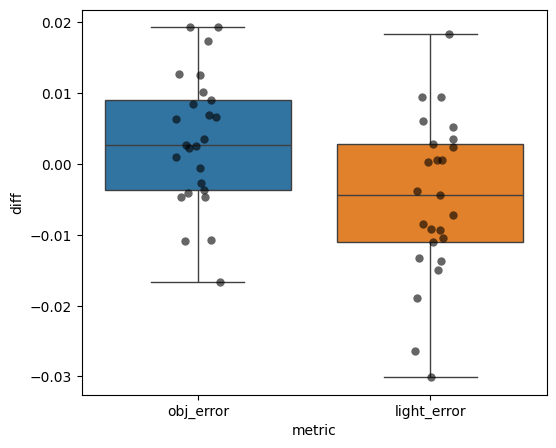

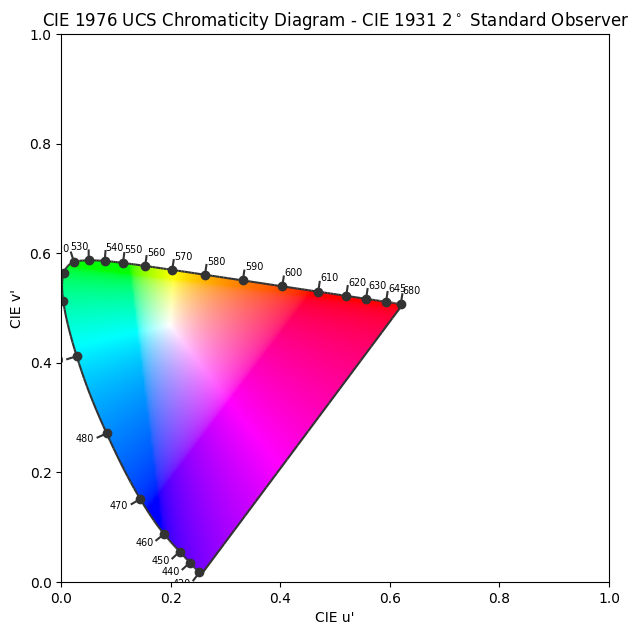

Saved glossy all-illumination mean-uv plot: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/uv_all_illuminations_mean_obj_uvs_glossy.png


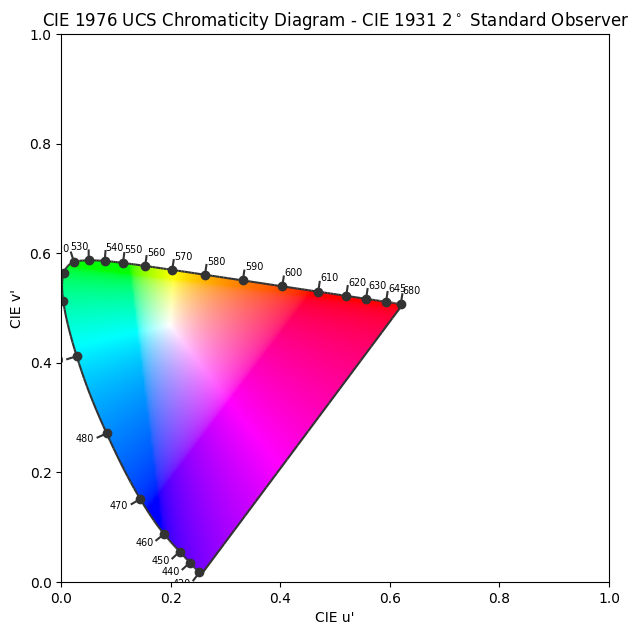

Saved glossy all-illumination all-points plot: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/uv_all_illuminations_mean_obj_uvs_glossy_allpoints.png


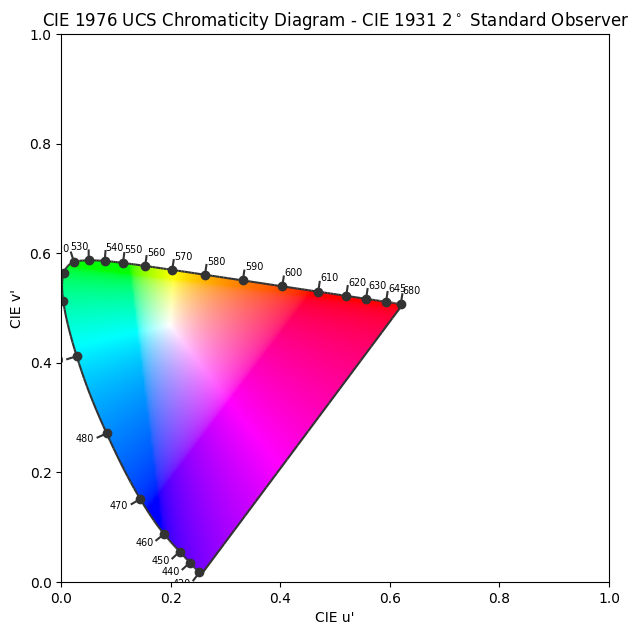

Saved matte all-illumination mean-uv plot: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/uv_all_illuminations_mean_obj_uvs_matte.png


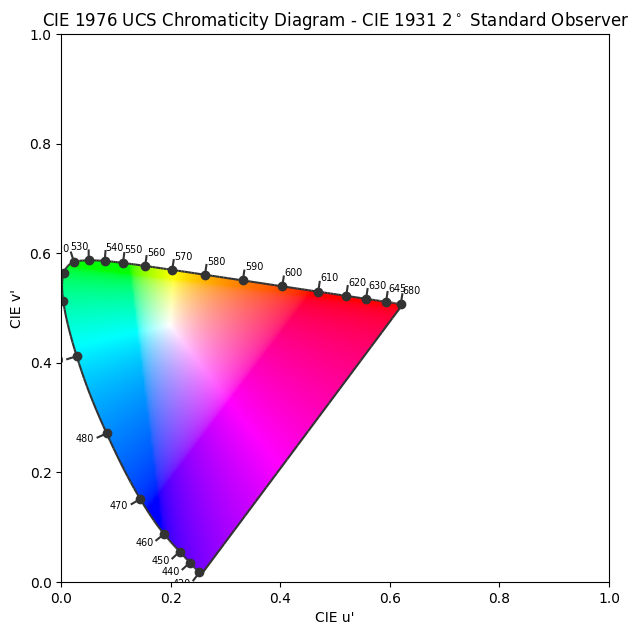

Saved matte all-illumination all-points plot: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/uv_all_illuminations_mean_obj_uvs_matte_allpoints.png


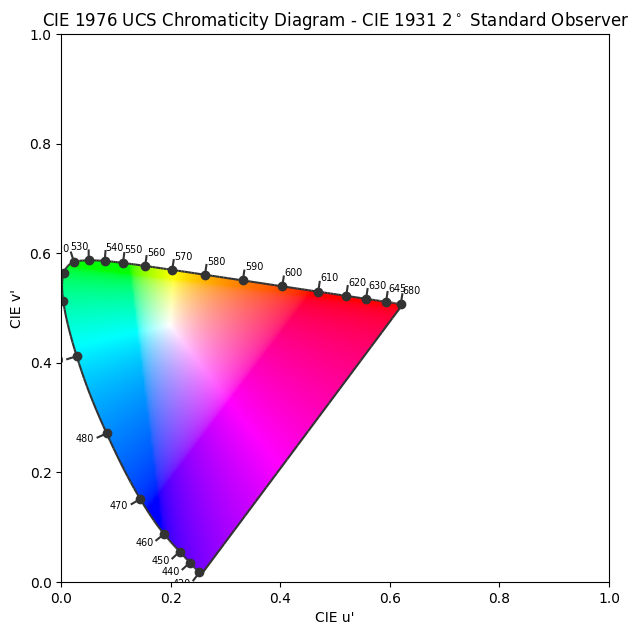

Saved combined all-points plot: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/uv_all_illuminations_mean_obj_uvs_allpoints.png


In [36]:
# Cell 12: Mean-UV plots for glossy-only and matte-only (across all illuminations)
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell (Cell 3) first.')
else:
    for alpha_val, suffix, title_label in [(0.01, 'glossy', 'Glossy (alpha=0.01)'), (0.99, 'matte', 'Matte (alpha=0.99)')]:
        sub_all = all_df[np.isclose(all_df['gt_alpha'], alpha_val)].copy()
        if sub_all.empty:
            print(f'No rows for alpha={alpha_val} — skipping {suffix} plot')
            continue
        # Prepare axes
        try:
            if _HAS_COLOUR:
                fig, ax = plot_chromaticity_diagram_CIE1976UCS()
            else:
                raise RuntimeError('colour not available')
        except Exception:
            fig, ax = plt.subplots(figsize=(6,6))
        
        # Plot GT object positions as diamonds
        gt_objs = sub_all[['gt_obj_u','gt_obj_v']].drop_duplicates().values
        for ou, ov in gt_objs:
            code, _ = uv_to_color_code(ou, ov)
            cgt = color_map.get(code, '#333333')
            ax.scatter([ou], [ov], c=cgt, s=140, marker='D', edgecolors='white', linewidths=0.6, label=None)
            try:
                ax.text(ou + 0.002, ov + 0.003, uv_to_color_label(ou, ov), fontsize=8, va='bottom')
            except Exception:
                pass
        
        # Compute mean predicted UV per mapped object color (W,Y,B,G,R)
        color_codes = ['W','Y','B','G','R']
        plotted_codes = []
        for code in color_codes:
            mask = sub_all.apply(lambda r: uv_to_color_code(r['gt_obj_u'], r['gt_obj_v'])[0] == code, axis=1)
            subset = sub_all[mask]
            if subset.empty:
                continue
            ux = subset['obj_u'].dropna().values
            vy = subset['obj_v'].dropna().values
            n = len(ux)
            if n == 0:
                continue
            mean_u = float(np.mean(ux))
            mean_v = float(np.mean(vy))
            sem_u = float(np.std(ux, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
            sem_v = float(np.std(vy, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
            c = color_map.get(code, '#333333')
            # mean as circle + errorbars
            ax.scatter([mean_u], [mean_v], c=c, s=120, marker='o', edgecolors='white', linewidths=0.6, zorder=20)
            try:
                ax.errorbar(mean_u, mean_v, xerr=sem_u, yerr=sem_v, fmt='none', ecolor='black', elinewidth=1.2, capsize=4, alpha=0.9, zorder=10)
            except Exception:
                if sem_u > 0:
                    ax.plot([mean_u - sem_u, mean_u + sem_u], [mean_v, mean_v], color='black', linewidth=1.2)
                if sem_v > 0:
                    ax.plot([mean_u, mean_u], [mean_v - sem_v, mean_v + sem_v], color='black', linewidth=1.2)
            ax.text(mean_u + 0.002, mean_v + 0.003, f'{code}', fontsize=9)
            plotted_codes.append(code)
        
        ax.set_xlim(0.11, 0.27)
        ax.set_ylim(0.39, 0.55)
        ax.set_xlabel("u'")
        ax.set_ylabel("v'")
        ax.set_title(f'Mean Predicted Object UVs (all illuminations) — {title_label} — GT diamonds + mean circles')
        
        # Legend
        try:
            import matplotlib.lines as mlines
            import matplotlib.patches as mpatches
            handles = []
            handles.append(mlines.Line2D([], [], color='k', marker='D', linestyle='None', markersize=8, markeredgecolor='white', label='GT object (diamonds)'))
            handles.append(mlines.Line2D([], [], color='k', marker='o', linestyle='None', markersize=7, markeredgecolor='white', label='Mean predicted (circles)'))
            for c in plotted_codes:
                handles.append(mpatches.Patch(facecolor=color_map.get(c, '#B0B0B0'), edgecolor='k', label=color_fullnames.get(c, c)))
            try:
                ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
            except Exception:
                ax.legend(handles=handles, loc='upper right', fontsize='small')
        except Exception:
            pass
        
        outp = plots_dir / f'uv_all_illuminations_mean_obj_uvs_{suffix}.png'
        try:
            fig.savefig(outp, dpi=300, bbox_inches='tight')
            print(f'Saved {suffix} all-illumination mean-uv plot: {outp}')
        except Exception as e:
            print(f'Failed to save {suffix} mean-uv plot: {e}')
        plt.close(fig)
        
        # Also create a plot showing all individual predicted object UV points for this alpha selection
        try:
            if _HAS_COLOUR:
                fig_all, ax_all = plot_chromaticity_diagram_CIE1976UCS()
            else:
                raise RuntimeError('colour not available')
        except Exception:
            fig_all, ax_all = plt.subplots(figsize=(6,6))
        
        # GT object positions
        for ou, ov in gt_objs:
            code, _ = uv_to_color_code(ou, ov)
            cgt = color_map.get(code, '#333333')
            ax_all.scatter([ou], [ov], c=cgt, s=140, marker='D', edgecolors='white', linewidths=0.6)
            try:
                ax_all.text(ou + 0.002, ov + 0.003, uv_to_color_label(ou, ov), fontsize=8, va='bottom')
            except Exception:
                pass
        
        # Plot all predicted object points colored by mapped object color
        for code in color_codes:
            mask_all = sub_all.apply(lambda r: uv_to_color_code(r['gt_obj_u'], r['gt_obj_v'])[0] == code, axis=1)
            subset_all = sub_all[mask_all]
            if subset_all.empty:
                continue
            try:
                ax_all.scatter(subset_all['obj_u'], subset_all['obj_v'], c=color_map.get(code, '#333333'), s=18, alpha=0.55, edgecolors='none')
            except Exception:
                for _, r in subset_all.iterrows():
                    try:
                        ax_all.scatter(r['obj_u'], r['obj_v'], c=color_map.get(code, '#333333'), s=18, alpha=0.55, edgecolors='none')
                    except Exception:
                        pass
        
        ax_all.set_xlim(0.11, 0.27)
        ax_all.set_ylim(0.39, 0.55)
        ax_all.set_xlabel("u'")
        ax_all.set_ylabel("v'")
        ax_all.set_title(f'All Predicted Object UVs (points) — {title_label}')
        
        try:
            import matplotlib.patches as mpatches
            handles_all = []
            for c in plotted_codes:
                handles_all.append(mpatches.Patch(facecolor=color_map.get(c, '#B0B0B0'), edgecolor='k', label=color_fullnames.get(c, c)))
            if handles_all:
                try:
                    ax_all.legend(handles=handles_all, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
                except Exception:
                    ax_all.legend(handles=handles_all, loc='upper right', fontsize='small')
        except Exception:
            pass
        
        outp_all = plots_dir / f'uv_all_illuminations_mean_obj_uvs_{suffix}_allpoints.png'
        try:
            fig_all.savefig(outp_all, dpi=300, bbox_inches='tight')
            print(f'Saved {suffix} all-illumination all-points plot: {outp_all}')
        except Exception as e:
            print(f'Failed to save {suffix} all-points plot: {e}')
        plt.close(fig_all)
    
    # Combined all-points plot: both glossy and matte on same axes
    try:
        if _HAS_COLOUR:
            fig_both, ax_both = plot_chromaticity_diagram_CIE1976UCS()
        else:
            fig_both, ax_both = plt.subplots(figsize=(6,6))
        # GT object positions (diamonds)
        gt_objs_all = all_df[['gt_obj_u','gt_obj_v']].drop_duplicates().values
        for ou, ov in gt_objs_all:
            code, _ = uv_to_color_code(ou, ov)
            cgt = color_map.get(code, '#333333')
            ax_both.scatter([ou], [ov], c=cgt, s=140, marker='D', edgecolors='white', linewidths=0.6)
        # Plot glossy and matte predicted points colored by mapped object color (different markers)
        sub_gloss = all_df[np.isclose(all_df['gt_alpha'], 0.01)].copy()
        sub_matte = all_df[np.isclose(all_df['gt_alpha'], 0.99)].copy()
        for code in ['W','Y','B','G','R']:
            mask_g = sub_gloss.apply(lambda r: uv_to_color_code(r['gt_obj_u'], r['gt_obj_v'])[0] == code, axis=1)
            mask_m = sub_matte.apply(lambda r: uv_to_color_code(r['gt_obj_u'], r['gt_obj_v'])[0] == code, axis=1)
            sg = sub_gloss[mask_g]
            sm = sub_matte[mask_m]
            col = color_map.get(code, '#333333')
            if not sg.empty:
                try:
                    ax_both.scatter(sg['obj_u'], sg['obj_v'], c=col, s=18, alpha=0.6, edgecolors='none', label=None, zorder=5)
                except Exception:
                    for _, r in sg.iterrows():
                        try:
                            ax_both.scatter(r['obj_u'], r['obj_v'], c=col, s=18, alpha=0.6, edgecolors='none', zorder=5)
                        except Exception:
                            pass
            if not sm.empty:
                try:
                    ax_both.scatter(sm['obj_u'], sm['obj_v'], c=col, marker='^', s=20, alpha=0.8, edgecolors='white', linewidths=0.2, label=None, zorder=6)
                except Exception:
                    for _, r in sm.iterrows():
                        try:
                            ax_both.scatter(r['obj_u'], r['obj_v'], c=col, marker='^', s=20, alpha=0.8, edgecolors='white', linewidths=0.2, zorder=6)
                        except Exception:
                            pass
        ax_both.set_xlim(0.11, 0.27)
        ax_both.set_ylim(0.39, 0.55)
        ax_both.set_xlabel("u'")
        ax_both.set_ylabel("v'")
        ax_both.set_title('All Predicted Object UVs (points) — glossy (circles) & matte (triangles)')
        # Build legend: object color patches + marker legend for glossy/matte
        try:
            import matplotlib.lines as mlines
            import matplotlib.patches as mpatches
            handles = []
            # marker legend entries
            handles.append(mlines.Line2D([], [], color='k', marker='o', linestyle='None', markersize=6, label='glossy (alpha=0.01)'))
            handles.append(mlines.Line2D([], [], color='k', marker='^', linestyle='None', markersize=6, label='matte (alpha=0.99)'))
            # color patches for object colors present
            present_codes = []
            for ou, ov in gt_objs_all:
                code, _ = uv_to_color_code(ou, ov)
                if code not in present_codes:
                    present_codes.append(code)
            for c in present_codes:
                handles.append(mpatches.Patch(facecolor=color_map.get(c, '#B0B0B0'), edgecolor='k', label=color_fullnames.get(c, c)))
            try:
                ax_both.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
            except Exception:
                ax_both.legend(handles=handles, loc='upper right', fontsize='small')
        except Exception:
            pass
        out_comb = plots_dir / 'uv_all_illuminations_mean_obj_uvs_allpoints.png'
        try:
            fig_both.savefig(out_comb, dpi=300, bbox_inches='tight')
            print(f'Saved combined all-points plot: {out_comb}')
        except Exception as e:
            print(f'Failed to save combined all-points plot: {e}')
        plt.close(fig_both)
    except Exception as e:
        print('Failed to create combined all-points plot:', e)

In [ ]:
# Cell 13: Swap roles — per-object predicted-light plots and overall mean-light UV plots (both/glossy/matte)
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell (Cell 3) first.')
else:
    # Per-object: for each GT object, plot predicted light UVs colored by mapped light color; GT lights as diamonds
    obj_keys = all_df[['gt_obj_u','gt_obj_v']].drop_duplicates().values
    n_obj_plots = 0
    for ou, ov in obj_keys:
        sub = all_df[(np.isclose(all_df['gt_obj_u'], ou)) & (np.isclose(all_df['gt_obj_v'], ov))].copy()
        if sub.empty:
            continue
        obj_label = uv_to_color_label(ou, ov)
        obj_code, _ = uv_to_color_code(ou, ov)

        try:
            if _HAS_COLOUR:
                fig, ax = plot_chromaticity_diagram_CIE1976UCS()
            else:
                raise RuntimeError('colour not available')
        except Exception:
            fig, ax = plt.subplots(figsize=(6,6))

        # predicted light points colored by mapped light color
        for (lu, lv), grp in sub.groupby(['gt_light_u','gt_light_v']):
            lcode, _ = uv_to_color_code(lu, lv)
            c = color_map.get(lcode, '#333333')
            ax.scatter(grp['light_u'], grp['light_v'], c=c, s=18, alpha=0.6, edgecolors='white', linewidths=0.2)

        # plot GT light positions
        gt_lights = sub[['gt_light_u','gt_light_v']].drop_duplicates().values
        for lu, lv in gt_lights:
            light_label = uv_to_color_label(lu, lv)
            lcode, _ = uv_to_color_code(lu, lv)
            c = color_map.get(lcode, '#333333')
            ax.scatter([lu], [lv], c=c, s=140, marker='D', edgecolors='white', linewidths=0.6)
            ax.text(lu + 0.002, lv + 0.003, light_label, fontsize=8, va='bottom')

        ax.set_xlim(0.11, 0.27)
        ax.set_ylim(0.39, 0.55)
        ax.set_xlabel("u'")
        ax.set_ylabel("v'")
        ax.set_title(f'Predicted & GT light UVs — object={obj_label}')

        # legend for light colors
        try:
            import matplotlib.patches as mpatches
            present_codes = []
            for lu, lv in gt_lights:
                code, _ = uv_to_color_code(lu, lv)
                if code not in present_codes:
                    present_codes.append(code)
            handles = [mpatches.Patch(facecolor=color_map.get(c, '#B0B0B0'), edgecolor='k', label=color_fullnames.get(c, c)) for c in present_codes]
            if handles:
                try:
                    ax.legend(handles=handles, title='Lights', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
                except Exception:
                    ax.legend(handles=handles, loc='upper right', fontsize='small')
        except Exception:
            pass

        outp = plots_dir / f'uv_by_obj_predicted_lights_{obj_code}_{ou:.2f}_{ov:.2f}.png'
        try:
            fig.savefig(outp, dpi=300, bbox_inches='tight')
            print(f'Saved per-object predicted-light plot for object {obj_label}: {outp}')
        except Exception as e:
            print(f'Failed to save per-object predicted-light plot for object {obj_label}: {e}')
        plt.close(fig)
        n_obj_plots += 1

        # Mean predicted light UV per mapped light color (for this object)
        try:
            try:
                if _HAS_COLOUR:
                    figm, axm = plot_chromaticity_diagram_CIE1976UCS()
                else:
                    raise RuntimeError('colour not available')
            except Exception:
                figm, axm = plt.subplots(figsize=(6,6))

            # Plot GT light positions as diamonds in the mean plot as well
            gt_lights = sub[['gt_light_u','gt_light_v']].drop_duplicates().values
            for lu, lv in gt_lights:
                lcode, _ = uv_to_color_code(lu, lv)
                cgt = color_map.get(lcode, '#333333')
                axm.scatter([lu], [lv], c=cgt, s=140, marker='D', edgecolors='white', linewidths=0.6)
                try:
                    axm.text(lu + 0.002, lv + 0.003, uv_to_color_label(lu, lv), fontsize=8, va='bottom')
                except Exception:
                    pass

            color_codes = ['W','Y','B','G','R']
            for code in color_codes:
                mask = sub.apply(lambda r: uv_to_color_code(r['gt_light_u'], r['gt_light_v'])[0] == code, axis=1)
                subset = sub[mask]
                if subset.empty:
                    continue
                lx = subset['light_u'].dropna().values
                ly = subset['light_v'].dropna().values
                n = len(lx)
                if n == 0:
                    continue
                mean_u = float(np.mean(lx))
                mean_v = float(np.mean(ly))
                sem_u = float(np.std(lx, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
                sem_v = float(np.std(ly, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
                c = color_map.get(code, '#333333')
                axm.scatter([mean_u], [mean_v], c=c, s=100, marker='o', edgecolors='white', linewidths=0.6, zorder=20)
                try:
                    axm.errorbar(mean_u, mean_v, xerr=sem_u, yerr=sem_v, fmt='none', ecolor='black', elinewidth=1.2, capsize=4, alpha=0.9)
                except Exception:
                    if sem_u > 0:
                        axm.plot([mean_u - sem_u, mean_u + sem_u], [mean_v, mean_v], color='black', linewidth=1.2)
                    if sem_v > 0:
                        axm.plot([mean_u, mean_u], [mean_v - sem_v, mean_v + sem_v], color='black', linewidth=1.2)
                axm.text(mean_u + 0.002, mean_v + 0.003, f"{code}", fontsize=9)

            axm.set_xlim(0.11, 0.27)
            axm.set_ylim(0.39, 0.55)
            axm.set_xlabel("u'")
            axm.set_ylabel("v'")
            axm.set_title(f"Mean Predicted Light UVs by Light Color — object={obj_label}")
            out_mean = plots_dir / f'uv_by_obj_mean_light_uvs_{obj_code}_{ou:.2f}_{ov:.2f}.png'
            try:
                figm.savefig(out_mean, dpi=300, bbox_inches='tight')
                print(f'Saved mean-light plot for object {obj_label}: {out_mean}')
            except Exception as e:
                print(f'Failed to save mean-light plot for object {obj_label}: {e}')
            plt.close(figm)
        except Exception as e:
            print(f'Failed to create mean-light plot for object {obj_label}: {e}')

    print(f'Saved {n_obj_plots} per-object predicted-light plot(s)')

    # Overall mean-light UV plots across objects: both, glossy-only, matte-only
    for df_label, df_sel in [('both', all_df), ('glossy', all_df[all_df['gt_alpha'] == 0.01]), ('matte', all_df[all_df['gt_alpha'] == 0.99])]:
        if df_sel.empty:
            print(f'No rows for {df_label} — skipping overall mean-light plot')
            continue
        try:
            if _HAS_COLOUR:
                fig, ax = plot_chromaticity_diagram_CIE1976UCS()
            else:
                raise RuntimeError('colour not available')
        except Exception:
            fig, ax = plt.subplots(figsize=(6,6))

        # Plot GT light positions (unique)
        gt_lights = df_sel[['gt_light_u','gt_light_v']].drop_duplicates().values
        for lu, lv in gt_lights:
            lcode, _ = uv_to_color_code(lu, lv)
            cgt = color_map.get(lcode, '#333333')
            ax.scatter([lu], [lv], c=cgt, s=140, marker='D', edgecolors='white', linewidths=0.6)
            try:
                ax.text(lu + 0.002, lv + 0.003, uv_to_color_label(lu, lv), fontsize=8, va='bottom')
            except Exception:
                pass

        # Mean predicted light UV per mapped light color across objects
        color_codes = ['W','Y','B','G','R']
        plotted_codes = []
        for code in color_codes:
            mask = df_sel.apply(lambda r: uv_to_color_code(r['gt_light_u'], r['gt_light_v'])[0] == code, axis=1)
            subset = df_sel[mask]
            if subset.empty:
                continue
            lx = subset['light_u'].dropna().values
            ly = subset['light_v'].dropna().values
            n = len(lx)
            if n == 0:
                continue
            mean_u = float(np.mean(lx))
            mean_v = float(np.mean(ly))
            sem_u = float(np.std(lx, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
            sem_v = float(np.std(ly, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
            c = color_map.get(code, '#333333')
            ax.scatter([mean_u], [mean_v], c=c, s=120, marker='o', edgecolors='white', linewidths=0.6, zorder=20)
            try:
                ax.errorbar(mean_u, mean_v, xerr=sem_u, yerr=sem_v, fmt='none', ecolor='black', elinewidth=1.2, capsize=4, alpha=0.9, zorder=10)
            except Exception:
                if sem_u > 0:
                    ax.plot([mean_u - sem_u, mean_u + sem_u], [mean_v, mean_v], color='black', linewidth=1.2)
                if sem_v > 0:
                    ax.plot([mean_u, mean_u], [mean_v - sem_v, mean_v + sem_v], color='black', linewidth=1.2)
            ax.text(mean_u + 0.002, mean_v + 0.003, f'{code}', fontsize=9)
            plotted_codes.append(code)

        ax.set_xlim(0.11, 0.27)
        ax.set_ylim(0.39, 0.55)
        ax.set_xlabel("u'")
        ax.set_ylabel("v'")
        title_map = {'both': 'Both alphas', 'glossy': 'Glossy (0.01)', 'matte': 'Matte (0.99)'}
        ax.set_title(f'Mean Predicted Light UVs (across objects) — {title_map.get(df_label, df_label)}')

        # Legend
        try:
            import matplotlib.lines as mlines
            import matplotlib.patches as mpatches
            handles = []
            handles.append(mlines.Line2D([], [], color='k', marker='D', linestyle='None', markersize=8, markeredgecolor='white', label='GT light (diamonds)'))
            handles.append(mlines.Line2D([], [], color='k', marker='o', linestyle='None', markersize=7, markeredgecolor='white', label='Mean predicted (circles)'))
            for c in plotted_codes:
                handles.append(mpatches.Patch(facecolor=color_map.get(c, '#B0B0B0'), edgecolor='k', label=color_fullnames.get(c, c)))
            try:
                ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
            except Exception:
                ax.legend(handles=handles, loc='upper right', fontsize='small')
        except Exception:
            pass

        outp = plots_dir / f'uv_all_obj_mean_light_uvs_{df_label}.png',
        try:
            fig.savefig(outp, dpi=300, bbox_inches='tight')
            print(f'Saved overall mean-light plot ({df_label}): {outp}')
        except Exception as e:
            print(f'Failed to save overall mean-light plot ({df_label}): {e}')
        plt.close(fig)

        # Also create a plot showing all individual predicted points (scatter) for this selection
        try:
            if _HAS_COLOUR:
                fig_all, ax_all = plot_chromaticity_diagram_CIE1976UCS()
            else:
                raise RuntimeError('colour not available')
        except Exception:
            fig_all, ax_all = plt.subplots(figsize=(6,6))

        # GT light positions
        for lu, lv in gt_lights:
            lcode, _ = uv_to_color_code(lu, lv)
            cgt = color_map.get(lcode, '#333333')
            ax_all.scatter([lu], [lv], c=cgt, s=140, marker='D', edgecolors='white', linewidths=0.6)
            try:
                ax_all.text(lu + 0.002, lv + 0.003, uv_to_color_label(lu, lv), fontsize=8, va='bottom')
            except Exception:
                pass

        # Plot all predicted points colored by mapped light color
        for code in color_codes:
            mask_all = df_sel.apply(lambda r: uv_to_color_code(r['gt_light_u'], r['gt_light_v'])[0] == code, axis=1)
            subset_all = df_sel[mask_all]
            if subset_all.empty:
                continue
            try:
                ax_all.scatter(subset_all['light_u'], subset_all['light_v'], c=color_map.get(code, '#333333'), s=18, alpha=0.55, edgecolors='none')
            except Exception:
                # fallback to plotting per-point in a loop if vectorized scatter fails
                for _, r in subset_all.iterrows():
                    try:
                        ax_all.scatter(r['light_u'], r['light_v'], c=color_map.get(code, '#333333'), s=18, alpha=0.55, edgecolors='none')
                    except Exception:
                        pass

        ax_all.set_xlim(0.11, 0.27)
        ax_all.set_ylim(0.39, 0.55)
        ax_all.set_xlabel("u'")
        ax_all.set_ylabel("v'")
        ax_all.set_title(f"All Predicted Light UVs (points) — {title_map.get(df_label, df_label)}")

        # Legend for colors (use plotted_codes from mean-plot step if available)
        try:
            import matplotlib.patches as mpatches
            handles_all = []
            for c in plotted_codes:
                handles_all.append(mpatches.Patch(facecolor=color_map.get(c, '#B0B0B0'), edgecolor='k', label=color_fullnames.get(c, c)))
            if handles_all:
                try:
                    ax_all.legend(handles=handles_all, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
                except Exception:
                    ax_all.legend(handles=handles_all, loc='upper right', fontsize='small')
        except Exception:
            pass

        outp_all = plots_dir / f'uv_all_obj_mean_light_uvs_{df_label}_allpoints.png'
        try:
            fig_all.savefig(outp_all, dpi=300, bbox_inches='tight')
            print(f'Saved overall all-points plot ({df_label}): {outp_all}')
        except Exception as e:
            print(f'Failed to save overall all-points plot ({df_label}): {e}')
        plt.close(fig_all)

In [ ]:
# Cell X: Boxplot of per-trial light_error distributions (glossy vs matte)
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell (Cell 3) first.')
else:
    df = all_df.copy()
    # label surfaces
    def surf_label(a):
        try:
            if np.isclose(a, 0.01):
                return 'glossy'
            if np.isclose(a, 0.99):
                return 'matte'
        except Exception:
            pass
        return str(a)
    df['surface'] = df['gt_alpha'].apply(surf_label)
    sel = df[df['surface'].isin(['glossy','matte'])].copy()
    if sel.empty:
        print('No glossy/matte rows found — skipping boxplot')
    else:
        plt.figure(figsize=(6,6))
        # Use consistent palette matching other plots
        palette = {'glossy': 'deepskyblue', 'matte': 'orangered'}
        try:
            sns.boxplot(x='surface', y='light_error', data=sel, palette=[palette['glossy'], palette['matte']])
        except Exception:
            # fallback if seaborn palette argument differs
            sns.boxplot(x='surface', y='light_error', data=sel)
        # overlay individual points
        sns.stripplot(x='surface', y='light_error', data=sel, color='k', size=4, jitter=True, alpha=0.6)
        plt.xlabel('Surface')
        plt.ylabel('Light error (Euclidean in uv)')
        plt.title('Per-trial light_error distributions — glossy vs matte')
        outp = plots_dir / 'box_light_error_glossy_vs_matte.png'
        try:
            plt.savefig(outp, dpi=300, bbox_inches='tight')
            print(f'Saved boxplot: {outp}')
        except Exception as e:
            print(f'Failed to save boxplot: {e}')
        plt.close()

In [ ]:
# Cell Y: Combined boxplots for obj_error and light_error (glossy vs matte) — no individual points
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell (Cell 3) first.')
else:
    box_df = all_df[all_df['gt_alpha'].isin([0.01, 0.99])].copy()
    if box_df.empty:
        print('No per-trial rows for alpha=0.01 or 0.99 to plot combined boxplots.')
    else:
        metrics = ['obj_error', 'light_error']
        # compute a common y-lim across both metrics so both subplots share the same vertical scale
        try:
            ymins = [box_df[m].min() for m in metrics]
            ymaxs = [box_df[m].max() for m in metrics]
            if all(np.isfinite(ymins)) and all(np.isfinite(ymaxs)):
                y_min_combined = np.nanmin(ymins)
                y_max_combined = np.nanmax(ymaxs)
                pad = max(1e-6, (y_max_combined - y_min_combined) * 0.05)
                common_ylim = (max(0.0, y_min_combined - pad), y_max_combined + pad)
            else:
                common_ylim = None
        except Exception:
            common_ylim = None

        fig, axes = plt.subplots(1, 2, figsize=(12,5))
        for ax, metric in zip(axes, metrics):
            try:
                sns.boxplot(x='gt_alpha', y=metric, data=box_df, showcaps=True, whis=1.5, ax=ax)
            except Exception:
                # fallback to matplotlib boxplot if seaborn fails
                data_glossy = box_df.loc[box_df['gt_alpha']==0.01, metric].dropna().values
                data_matte = box_df.loc[box_df['gt_alpha']==0.99, metric].dropna().values
                ax.boxplot([data_glossy, data_matte], labels=['0.01','0.99'])

            ax.set_xlabel('alpha (glossiness)')
            ax.set_ylabel(metric)
            title_map = {'obj_error': 'Obj error — glossy vs matte', 'light_error': 'Light error — glossy vs matte'}
            ax.set_title(title_map.get(metric, metric))

            # compute p-value
            try:
                g_glossy = box_df.loc[box_df['gt_alpha']==0.01, metric].dropna().values
                g_matte = box_df.loc[box_df['gt_alpha']==0.99, metric].dropna().values
                pval = compute_pvalue(g_glossy, g_matte, n_perm=2000)
            except Exception:
                pval = float('nan')
            stars = p_to_stars(pval)

            # annotate p-value near top of axis using the shared y-lim
            try:
                if common_ylim is not None:
                    ax.set_ylim(common_ylim)
                    y_top = common_ylim[1]
                    y_bottom = common_ylim[0]
                else:
                    y_bottom = box_df[metric].min()
                    y_top = box_df[metric].max()

                h = (y_top - y_bottom) * 0.06 if (y_top > y_bottom) else 0.01
                _annotate_pvalue_on_ax(ax, 0, 1, y_top - h * 0.5, h, f'{stars} (p={pval:.3g})')
            except Exception:
                pass
        plt.tight_layout()
        outp = plots_dir / 'box_both_errors_glossy_vs_matte.png'
        try:
            fig.savefig(outp, dpi=200, bbox_inches='tight')
            print(f'Saved combined boxplots: {outp}')
        except Exception as e:
            print(f'Failed to save combined boxplots: {e}')
        plt.close(fig)


In [ ]:
# u'v' plot with nothing and u'v' plot with ground truth only
# This cell creates two PNGs in `plots/`: a background-only uv diagram,
# and a uv diagram showing only ground-truth object colors as diamonds.

# Background-only plot (will use colour diagram if available, otherwise blank axes)
try:
    if _HAS_COLOUR:
        fig, ax = plot_chromaticity_diagram_CIE1976UCS()
    else:
        raise RuntimeError('colour not available')
except Exception:
    fig, ax = plt.subplots(figsize=(6,6))
# Use the UV ranges used elsewhere in the notebook
ax.set_xlim(0.11, 0.27)
ax.set_ylim(0.39, 0.55)
ax.set_xlabel("u'")
ax.set_ylabel("v'")
ax.set_title("u'v' color space")
out_bg = plots_dir / 'uv_background_only.png'
try:
    fig.savefig(out_bg, dpi=300, bbox_inches='tight')
    print(f'Saved background-only uv plot: {out_bg}')
except Exception as e:
    print(f'Failed to save background-only plot: {e}')
plt.close(fig)

# Ground-truth diamonds only (objects) — requires `all_df` built by the scanning cell
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell (Cell 3) first to generate GT coordinates. Ground-truth-only plot skipped.')
else:
    try:
        gt_objs = all_df[['gt_obj_u','gt_obj_v']].drop_duplicates().values
        try:
            if _HAS_COLOUR:
                fig2, ax2 = plot_chromaticity_diagram_CIE1976UCS()
            else:
                raise RuntimeError('colour not available')
        except Exception:
            fig2, ax2 = plt.subplots(figsize=(6,6))
        for ou, ov in gt_objs:
            code, _ = uv_to_color_code(ou, ov)
            c = color_map.get(code, '#333333')
            ax2.scatter([ou], [ov], c=c, s=200, marker='D', edgecolors='white', linewidths=0.8)
            try:
                ax2.text(ou + 0.002, ov + 0.003, uv_to_color_label(ou, ov), fontsize=8, va='bottom')
            except Exception:
                pass
        ax2.set_xlim(0.11, 0.27)
        ax2.set_ylim(0.39, 0.55)
        ax2.set_xlabel("u'")
        ax2.set_ylabel("v'")
        ax2.set_title("u'v' — Ground-truth object colors (diamonds)")
        out_gt = plots_dir / 'uv_gt_diamonds.png'
        try:
            fig2.savefig(out_gt, dpi=300, bbox_inches='tight')
            print(f'Saved ground-truth diamonds plot: {out_gt}')
        except Exception as e:
            print(f'Failed to save ground-truth diamonds plot: {e}')
        plt.close(fig2)
    except Exception as e:
        print('Failed to create GT diamonds plot:', e)

In [ ]:
# Cell Z: Compute Color Constancy Index (CCI) per trial (skip white lights)
# Formula: CCI = 1 - |obj_error| / |GT_light - White_reference|
if 'all_df' not in globals():
    print('`all_df` not found - run the scanning cell (Cell 3) first. CCI not computed.')
else:
    try:
        # white reference (W) is defined in the color-helpers cell
        lightW = tuple(W)
        # Euclidean distance from GT light to white reference
        all_df['light_to_white_dist'] = np.sqrt((all_df['gt_light_u'] - lightW[0])**2 + (all_df['gt_light_v'] - lightW[1])**2)
        # Map GT light to nearest named color code
        all_df['gt_light_code'] = all_df.apply(lambda r: uv_to_color_code(r['gt_light_u'], r['gt_light_v'])[0], axis=1)
        # Initialize CCI column
        all_df['cci'] = np.nan
        # Compute CCI where GT light is not white and distance > 0 to avoid division by zero
        mask = (all_df['gt_light_code'] != 'W') & (all_df['light_to_white_dist'] > 0)
        all_df.loc[mask, 'cci'] = 1.0 - (all_df.loc[mask, 'obj_error'].abs() / all_df.loc[mask, 'light_to_white_dist'].abs())
        # Report counts and a quick summary
        n_total = len(all_df)
        n_valid = int(mask.sum())
        print(f'Computed CCI for {n_valid} / {n_total} trials (excluded white lights or zero-distance)')
        try:
            print(all_df['cci'].describe())
        except Exception:
            pass
        # Save per-trial CCI CSV to processed_results (archive_dir)
        out_csv = archive_dir / 'cci_per_trial.csv'
        try:
            all_df.to_csv(out_csv, index=False)
            print(f'Saved per-trial CCI CSV: {out_csv}')
        except Exception as e:
            print(f'Failed to save per-trial CCI CSV: {e}')
        # Save aggregated mean CCI per folder
        try:
            agg_cci = all_df.groupby('folder')['cci'].mean().reset_index(name='mean_cci')
            out_agg = archive_dir / 'cci_mean_by_folder.csv'
            agg_cci.to_csv(out_agg, index=False)
            print(f'Saved aggregated mean CCI by folder: {out_agg}')
        except Exception as e:
            print(f'Failed to save aggregated CCI: {e}')
    except Exception as e:
        print('Failed to compute CCI:', e)

In [ ]:
# Cell L: Mean predicted LIGHT UVs (both/glossy/matte) — GT diamonds + mean circles with SEM
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell (Cell 3) first.')
else:
    # Prepare three plots: both, glossy-only, matte-only
    title_map = {'both': 'Both alphas', 'glossy': 'Glossy (0.01)', 'matte': 'Matte (0.99)'}
    color_codes = ['W','Y','B','G','R']
    for df_label, df_sel in [('both', all_df), ('glossy', all_df[all_df['gt_alpha'] == 0.01]), ('matte', all_df[all_df['gt_alpha'] == 0.99])]:
        if df_sel.empty:
            print(f'No rows for {df_label} — skipping mean-light plot')
            continue
        try:
            if _HAS_COLOUR:
                fig, ax = plot_chromaticity_diagram_CIE1976UCS()
            else:
                raise RuntimeError('colour not available')
        except Exception:
            fig, ax = plt.subplots(figsize=(6,6))

        # Plot GT light positions (unique) as diamonds
        gt_lights = df_sel[['gt_light_u','gt_light_v']].drop_duplicates().values
        for lu, lv in gt_lights:
            lcode, _ = uv_to_color_code(lu, lv)
            cgt = color_map.get(lcode, '#333333')
            ax.scatter([lu], [lv], c=cgt, s=140, marker='D', edgecolors='white', linewidths=0.6)
            try:
                ax.text(lu + 0.002, lv + 0.003, uv_to_color_label(lu, lv), fontsize=8, va='bottom')
            except Exception:
                pass

        # For each mapped light color code compute mean predicted light_u/light_v and SEM
        plotted_codes = []
        for code in color_codes:
            mask = df_sel.apply(lambda r: uv_to_color_code(r['gt_light_u'], r['gt_light_v'])[0] == code, axis=1)
            subset = df_sel[mask]
            if subset.empty:
                continue
            lx = subset['light_u'].dropna().values
            ly = subset['light_v'].dropna().values
            n = len(lx)
            if n == 0:
                continue
            mean_u = float(np.mean(lx))
            mean_v = float(np.mean(ly))
            sem_u = float(np.std(lx, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
            sem_v = float(np.std(ly, ddof=1) / np.sqrt(n)) if n > 1 else 0.0
            c = color_map.get(code, '#333333')
            # plot mean as circle with errorbars
            ax.scatter([mean_u], [mean_v], c=c, s=120, marker='o', edgecolors='white', linewidths=0.6, zorder=20)
            try:
                ax.errorbar(mean_u, mean_v, xerr=sem_u, yerr=sem_v, fmt='none', ecolor='black', elinewidth=1.2, capsize=4, alpha=0.9, zorder=10)
            except Exception:
                if sem_u > 0:
                    ax.plot([mean_u - sem_u, mean_u + sem_u], [mean_v, mean_v], color='black', linewidth=1.2)
                if sem_v > 0:
                    ax.plot([mean_u, mean_u], [mean_v - sem_v, mean_v + sem_v], color='black', linewidth=1.2)
            ax.text(mean_u + 0.002, mean_v + 0.003, f'{code}', fontsize=9)
            plotted_codes.append(code)

        ax.set_xlim(0.11, 0.27)
        ax.set_ylim(0.39, 0.55)
        ax.set_xlabel("u'")
        ax.set_ylabel("v'")
        ax.set_title(f"Mean Predicted Light UVs (across objects) — {title_map.get(df_label, df_label)}")

        # Legend
        try:
            import matplotlib.lines as mlines
            import matplotlib.patches as mpatches
            handles = []
            handles.append(mlines.Line2D([], [], color='k', marker='D', linestyle='None', markersize=8, markeredgecolor='white', label='GT light (diamonds)'))
            handles.append(mlines.Line2D([], [], color='k', marker='o', linestyle='None', markersize=7, markeredgecolor='white', label='Mean predicted (circles)'))
            for c in plotted_codes:
                handles.append(mpatches.Patch(facecolor=color_map.get(c, '#B0B0B0'), edgecolor='k', label=color_fullnames.get(c, c)))
            try:
                ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
            except Exception:
                ax.legend(handles=handles, loc='upper right', fontsize='small')
        except Exception:
            pass

        outp = plots_dir / f'uv_all_illuminations_mean_light_uvs_{df_label}.png'
        try:
            fig.savefig(outp, dpi=300, bbox_inches='tight')
            print(f'Saved mean-light plot ({df_label}): {outp}')
        except Exception as e:
            print(f'Failed to save mean-light plot ({df_label}): {e}')
        plt.close(fig)

        # Also save a plot of all individual predicted light points colored by mapped light color
        try:
            if _HAS_COLOUR:
                fig_all, ax_all = plot_chromaticity_diagram_CIE1976UCS()
            else:
                raise RuntimeError('colour not available')
        except Exception:
            fig_all, ax_all = plt.subplots(figsize=(6,6))

        # GT light positions
        for lu, lv in gt_lights:
            lcode, _ = uv_to_color_code(lu, lv)
            cgt = color_map.get(lcode, '#333333')
            ax_all.scatter([lu], [lv], c=cgt, s=140, marker='D', edgecolors='white', linewidths=0.6)
            try:
                ax_all.text(lu + 0.002, lv + 0.003, uv_to_color_label(lu, lv), fontsize=8, va='bottom')
            except Exception:
                pass

        for code in color_codes:
            mask_all = df_sel.apply(lambda r: uv_to_color_code(r['gt_light_u'], r['gt_light_v'])[0] == code, axis=1)
            subset_all = df_sel[mask_all]
            if subset_all.empty:
                continue
            try:
                ax_all.scatter(subset_all['light_u'], subset_all['light_v'], c=color_map.get(code, '#333333'), s=18, alpha=0.55, edgecolors='none')
            except Exception:
                for _, r in subset_all.iterrows():
                    try:
                        ax_all.scatter(r['light_u'], r['light_v'], c=color_map.get(code, '#333333'), s=18, alpha=0.55, edgecolors='none')
                    except Exception:
                        pass

        ax_all.set_xlim(0.11, 0.27)
        ax_all.set_ylim(0.39, 0.55)
        ax_all.set_xlabel("u'")
        ax_all.set_ylabel("v'")
        ax_all.set_title(f'All Predicted Light UVs (points) — {title_map.get(df_label, df_label)}')
        try:
            import matplotlib.patches as mpatches
            handles_all = []
            for c in plotted_codes:
                handles_all.append(mpatches.Patch(facecolor=color_map.get(c, '#B0B0B0'), edgecolor='k', label=color_fullnames.get(c, c)))
            if handles_all:
                try:
                    ax_all.legend(handles=handles_all, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
                except Exception:
                    ax_all.legend(handles=handles_all, loc='upper right', fontsize='small')
        except Exception:
            pass

        outp_all = plots_dir / f'uv_all_illuminations_mean_light_uvs_{df_label}_allpoints.png'
        try:
            fig_all.savefig(outp_all, dpi=300, bbox_inches='tight')
            print(f'Saved mean-light all-points plot ({df_label}): {outp_all}')
        except Exception as e:
            print(f'Failed to save mean-light all-points plot ({df_label}): {e}')
        plt.close(fig_all)


In [ ]:
# plot of obj_error vs light_error per trial

In [22]:
# Cell M: Scatter plot of obj_error vs light_error (all trials)
if 'all_df' not in globals():
    print("`all_df` not found — run the scanning cell (Cell 3) first to build per-trial rows.")
else:
    df = all_df.copy()
    # label surfaces (glossy/matte/other)
    def surf_label(a):
        try:
            if np.isclose(a, 0.01):
                return 'glossy'
            if np.isclose(a, 0.99):
                return 'matte'
        except Exception:
            pass
        return 'other'

    df['surface'] = df['gt_alpha'].apply(surf_label)
    palette = {'glossy': 'deepskyblue', 'matte': 'orangered', 'other': 'gray'}

    plt.figure(figsize=(6,6))
    try:
        sns.scatterplot(data=df, x='obj_error', y='light_error', hue='surface', palette=palette, alpha=0.75, s=36, edgecolor='k', linewidth=0.2)
    except Exception:
        # fallback to matplotlib scatter if seaborn call fails
        for surf, grp in df.groupby('surface'):
            c = palette.get(surf, 'gray')
            plt.scatter(grp['obj_error'], grp['light_error'], c=c, label=surf, alpha=0.75, s=36, edgecolors='k', linewidths=0.2)
        plt.legend()

    plt.xlabel('obj_error')
    plt.ylabel('light_error')
    plt.title('Obj error vs Light error — all trials')

    # diagonal line for reference
    maxlim = max(df['obj_error'].max() if df['obj_error'].size else 0.0, df['light_error'].max() if df['light_error'].size else 0.0)
    maxlim = max(maxlim, 1e-6)
    plt.plot([0, maxlim], [0, maxlim], ls='--', color='gray', linewidth=0.8)

    # compute and print correlation
    try:
        corr = df[['obj_error', 'light_error']].dropna().corr().iloc[0,1]
        print(f'Pearson corr(obj_error, light_error) = {corr:.3f}')
    except Exception:
        pass

    outp = plots_dir / 'scatter_obj_vs_light_all.png'
    try:
        plt.savefig(outp, dpi=200, bbox_inches='tight')
        print(f'Saved scatter plot: {outp}')
    except Exception as e:
        print(f'Failed to save scatter plot: {e}')
    plt.close()


Pearson corr(obj_error, light_error) = 0.117
Saved scatter plot: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/scatter_obj_vs_light_all.png
Saved scatter plot: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/scatter_obj_vs_light_all.png


In [24]:
# Cell N: Glossy vs Matte — mean LIGHT error scatter (per (obj,light) pair)
if 'all_df' not in globals():
    print("`all_df` not found — run the scanning cell (Cell 3) first.")
else:
    try:
        # aggregate mean light_error per (obj,light,alpha)
        agg_light = all_df.groupby(['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v','gt_alpha'])['light_error'].mean().reset_index(name='mean_light_error')
        # pivot to have glossy(0.01) and matte(0.99) as columns
        wide = agg_light.pivot_table(index=['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v'], columns='gt_alpha', values='mean_light_error')
        col_glossy = 0.01
        col_matte = 0.99
        if col_glossy in wide.columns and col_matte in wide.columns:
            df_wide = wide.reset_index()[['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v', col_glossy, col_matte]].dropna()
            x = df_wide[col_glossy].values
            y = df_wide[col_matte].values
            import matplotlib.patches as mpatches
            fig, ax = plt.subplots(figsize=(6,6))
            # diagonal reference
            mval = max(np.nanmax(x) if len(x) else 0.0, np.nanmax(y) if len(y) else 0.0)
            mval = max(mval, 1e-6)
            ax.plot([0, mval], [0, mval], ls='--', color='gray')
            ax.set_xlabel(f'mean light error (glossy={col_glossy})')
            ax.set_ylabel(f'mean light error (matte={col_matte})')
            ax.set_title('Glossy vs Matte: mean LIGHT error per (obj,light) pair')
            pad = mval * 0.06
            ax.set_xlim(max(0, 0 - pad), mval + pad)
            ax.set_ylim(max(0, 0 - pad), mval + pad)
            ax.set_aspect('equal', adjustable='box')

            # Draw each point with left/right halves showing object and light mapped colors
            for _, row in df_wide.iterrows():
                xi = float(row[col_glossy])
                yi = float(row[col_matte])
                u_obj = float(row['gt_obj_u'])
                v_obj = float(row['gt_obj_v'])
                u_light = float(row['gt_light_u'])
                v_light = float(row['gt_light_v'])
                obj_code, _ = uv_to_color_code(u_obj, v_obj)
                light_code, _ = uv_to_color_code(u_light, v_light)
                cobj = color_map.get(obj_code, '#B0B0B0')
                clight = color_map.get(light_code, '#B0B0B0')
                # small radius relative to plot scale
                r = max(mval, 1.0) * 0.0009
                w1 = mpatches.Wedge((xi, yi), r, 90, 270, facecolor=cobj, edgecolor='k', linewidth=0.3)
                w2 = mpatches.Wedge((xi, yi), r, -90, 90, facecolor=clight, edgecolor='k', linewidth=0.3)
                ax.add_patch(w1)
                ax.add_patch(w2)

            # legend explaining halves
            try:
                left_patch = mpatches.Patch(facecolor='gray', edgecolor='k', label='object color (left half)')
                right_patch = mpatches.Patch(facecolor='lightgray', edgecolor='k', label='light color (right half)')
                ax.legend(handles=[left_patch, right_patch], bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize='small')
            except Exception:
                try:
                    ax.legend(handles=[left_patch, right_patch], loc='upper left', fontsize='small')
                except Exception:
                    pass

            outp = plots_dir / 'glossy_vs_matte_mean_light_error_scatter.png'
            try:
                fig.savefig(outp, dpi=200, bbox_inches='tight')
                print(f'Saved glossy vs matte mean light error scatter: {outp}')
            except Exception as e:
                print(f'Failed to save glossy vs matte mean light error scatter: {e}')
            plt.close(fig)
        else:
            print('Not enough alpha columns present for glossy vs matte mean-light scatter (need 0.01 and 0.99).')
    except Exception as e:
        print(f'Failed to create glossy_vs_matte_mean_light_error_scatter: {e}')


Saved glossy vs matte mean light error scatter: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/glossy_vs_matte_mean_light_error_scatter.png


In [26]:
# Cell P: Per-illumination scatter: obj_error vs light_error for each GT illumination
if 'all_df' not in globals():
    print("`all_df` not found — run the scanning cell (Cell 3) first to build per-trial rows.")
else:
    lights = all_df[['gt_light_u','gt_light_v']].drop_duplicates().values
    def surf_label(a):
        try:
            if np.isclose(a, 0.01):
                return 'glossy'
            if np.isclose(a, 0.99):
                return 'matte'
        except Exception:
            pass
        return 'other'

    for lu, lv in lights:
        sub = all_df[np.isclose(all_df['gt_light_u'], lu) & np.isclose(all_df['gt_light_v'], lv)].copy()
        if sub.empty:
            continue
        light_code, _ = uv_to_color_code(lu, lv)
        light_label = uv_to_color_label(lu, lv)

        # label surface for coloring
        sub['surface'] = sub['gt_alpha'].apply(surf_label)
        palette = {'glossy': 'deepskyblue', 'matte': 'orangered', 'other': 'gray'}

        fig, ax = plt.subplots(figsize=(6,6))
        try:
            sns.scatterplot(data=sub, x='obj_error', y='light_error', hue='surface', palette=palette, alpha=0.8, s=36, edgecolor='k', linewidth=0.2, ax=ax)
        except Exception:
            for surf, grp in sub.groupby('surface'):
                c = palette.get(surf, 'gray')
                ax.scatter(grp['obj_error'], grp['light_error'], c=c, label=surf, alpha=0.8, s=36, edgecolors='k', linewidths=0.2)
            try:
                ax.legend()
            except Exception:
                pass

        ax.set_xlabel('obj_error')
        ax.set_ylabel('light_error')
        ax.set_title(f'Obj error vs Light error — light={light_label}')

        # diagonal reference
        maxlim = max(sub['obj_error'].max() if sub['obj_error'].size else 0.0, sub['light_error'].max() if sub['light_error'].size else 0.0)
        maxlim = max(maxlim, 1e-6)
        ax.plot([0, maxlim], [0, maxlim], ls='--', color='gray', linewidth=0.8)

        # correlation
        try:
            corr = sub[['obj_error', 'light_error']].dropna().corr().iloc[0,1]
            print(f'Light {light_label}: Pearson corr(obj_error, light_error) = {corr:.3f} (n={len(sub)})')
        except Exception:
            print(f'Light {light_label}: could not compute correlation (n={len(sub)})')

        outp = plots_dir / f'scatter_obj_vs_light_light_{light_code}_{lu:.3f}_{lv:.3f}.png'
        try:
            fig.savefig(outp, dpi=200, bbox_inches='tight')
            print(f'Saved per-light scatter: {outp}')
        except Exception as e:
            print(f'Failed to save per-light scatter for {light_label}: {e}')
        plt.close(fig)


Light White (W): Pearson corr(obj_error, light_error) = -0.070 (n=80)
Saved per-light scatter: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/scatter_obj_vs_light_light_W_0.190_0.470.png
Light Yellow (Y): Pearson corr(obj_error, light_error) = 0.293 (n=80)
Light Yellow (Y): Pearson corr(obj_error, light_error) = 0.293 (n=80)
Saved per-light scatter: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/scatter_obj_vs_light_light_Y_0.230_0.510.png
Light Red (R): Pearson corr(obj_error, light_error) = 0.026 (n=80)
Saved per-light scatter: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/scatter_obj_vs_light_light_Y_0.230_0.510.png
Light Red (R): Pearson corr(obj_error, light_error) = 0.026 (n=80)
Saved per-light scatter: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/scatter_obj_vs_light_light_R_0.230_0.430.png
Light Green (G): Pearson corr(obj_error, light_error) = 0.022 (n=80)
Saved per-light scatter: /Users/jinnie/Desktop/25FA/PSYC 56

In [35]:
# Cell: Compute glossy - matte differences (mean) for obj_error and light_error and plot them as boxplots
if 'all_df' not in globals():
    print('`all_df` not found — run the scanning cell (Cell 3) first.')
else:
    try:
        # Aggregate mean errors per (obj, light, alpha)
        agg_err = all_df.groupby(['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v','gt_alpha']).agg({'obj_error':'mean','light_error':'mean'}).reset_index()
        # Pivot so alpha values become columns (0.01 = glossy, 0.99 = matte)
        obj_wide = agg_err.pivot_table(index=['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v'], columns='gt_alpha', values='obj_error')
        light_wide = agg_err.pivot_table(index=['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v'], columns='gt_alpha', values='light_error')
        a_gloss = 0.01
        a_matte = 0.99
        # Prepare named columns for clarity
        obj2 = obj_wide.reset_index().rename(columns={a_gloss: 'obj_glossy', a_matte: 'obj_matte'})
        light2 = light_wide.reset_index().rename(columns={a_gloss: 'light_glossy', a_matte: 'light_matte'})
        # Merge on the four coordinates to get only pairs present in both
        df_pairs = pd.merge(obj2, light2, on=['gt_obj_u','gt_obj_v','gt_light_u','gt_light_v'], how='inner')
        # Drop rows with missing mean values
        df_pairs = df_pairs.dropna(subset=['obj_glossy','obj_matte','light_glossy','light_matte']).copy()
        if df_pairs.empty:
            print('No matching glossy/matte pairs available to compute differences.')
        else:
            # compute glossy - matte (note the sign change requested)
            df_pairs['diff_obj'] = df_pairs['obj_glossy'] - df_pairs['obj_matte']
            df_pairs['diff_light'] = df_pairs['light_glossy'] - df_pairs['light_matte']

            # One-sample test (mean vs 0): use SciPy t-test if available, otherwise sign-flip permutation
            def one_sample_pvalue(arr, n_perm=5000, seed=0):
                import numpy as _np
                a = _np.asarray(arr)[~_np.isnan(arr)]
                if a.size == 0:
                    return _np.nan
                if _HAS_SCIPY:
                    try:
                        tstat, pval = _ss.ttest_1samp(a, 0.0, nan_policy='omit')
                        return float(pval)
                    except Exception:
                        pass
                rng = _np.random.default_rng(seed)
                obs = a.mean()
                count = 0
                for _ in range(int(n_perm)):
                    signs = rng.choice([-1, 1], size=a.shape)
                    perm_mean = (a * signs).mean()
                    if abs(perm_mean) >= abs(obs):
                        count += 1
                return float((count + 1) / (n_perm + 1))

            diffs_obj = df_pairs['diff_obj'].dropna().values
            diffs_light = df_pairs['diff_light'].dropna().values
            p_obj = one_sample_pvalue(diffs_obj, n_perm=5000, seed=1)
            p_light = one_sample_pvalue(diffs_light, n_perm=5000, seed=2)
            stars_obj = p_to_stars(p_obj)
            stars_light = p_to_stars(p_light)
            print(f"Obj diff (glossy - matte): n={len(diffs_obj)}, mean={np.nanmean(diffs_obj):.4g}, p={p_obj:.3g}, sig={stars_obj}")
            print(f"Light diff (glossy - matte): n={len(diffs_light)}, mean={np.nanmean(diffs_light):.4g}, p={p_light:.3g}, sig={stars_light}")

            # Build a tidy DataFrame for seaborn boxplot
            n = len(df_pairs)
            data = pd.DataFrame({'metric': ['obj_error']*n + ['light_error']*n, 'diff': np.concatenate([df_pairs['diff_obj'].values, df_pairs['diff_light'].values])})

            # Plot boxplots side-by-side with individual points overlaid
            try:
                fig, ax = plt.subplots(figsize=(6,5))
                sns.boxplot(x='metric', y='diff', data=data, palette=['tab:blue','tab:orange'], ax=ax, showcaps=True, whis=1.5)
                sns.stripplot(x='metric', y='diff', data=data, color='k', size=6, jitter=True, alpha=0.6, ax=ax)
                # stronger zero line: thicker, dashed, higher z-order
                ax.axhline(0, color='red', linewidth=2.0, linestyle='--', zorder=10)
                ax.set_xlabel('Metric')
                ax.set_ylabel('Mean difference (glossy - matte)')
                ax.set_title('Distribution of glossy - matte mean differences')
                # annotate p-values above each box
                try:
                    xt = ax.get_xticks()
                    ymax = data['diff'].max() if data['diff'].size else 0.0
                    ymin = data['diff'].min() if data['diff'].size else 0.0
                    span = max(1e-6, (ymax - ymin))
                    ytext = ymax + span * 0.12
                    ax.text(xt[0], ytext, f"p={p_obj:.3g} {stars_obj}", ha='center', va='bottom', fontsize=9)
                    ax.text(xt[1], ytext, f"p={p_light:.3g} {stars_light}", ha='center', va='bottom', fontsize=9)
                except Exception:
                    pass
                plt.tight_layout()
                outp = plots_dir / 'diffs_obj_light_glossy_minus_matte_boxplot.png'
                try:
                    fig.savefig(outp, dpi=200, bbox_inches='tight')
                    print(f'Saved differences boxplot: {outp}')
                except Exception as e:
                    print(f'Failed to save differences boxplot: {e}')
                plt.close(fig)
            except Exception as e:
                print('Failed to create differences boxplot:', e)
    except Exception as e:
        print('Failed during difference calculations:', e)

Obj diff (glossy - matte): n=25, mean=-0.003266, p=0.0945, sig=.
Light diff (glossy - matte): n=25, mean=0.004916, p=0.041, sig=*


/var/folders/sy/6gx6mfld0sscbv1zzxzy4ftr0000gn/T/ipykernel_92631/3247733444.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='metric', y='diff', data=data, palette=['tab:blue','tab:orange'], ax=ax, showcaps=True, whis=1.5)


Saved differences boxplot: /Users/jinnie/Desktop/25FA/PSYC 5610/project/basic copy/plots/diffs_obj_light_glossy_minus_matte_boxplot.png
